# Feature Extraction: Multi-Scale Acoustic Feature Extraction (5.0s & 3.0s Windows)

This notebook extracts acoustic representations for training deep learning models across both 5.0-second and 3.0-second window scales:
1. Loads preprocessed audio snippets from `data/preprocessed/5-seconds/` and `data/preprocessed/3-seconds/`.
2. Discards snippets marked with ambiguous calls (`has_ambiguous == True`) to ensure clean target labels.
3. Extracts **Log-Mel Spectrogram** features using bioacoustic parameters from Carvalho & Gomes (2022).
4. Extracts **Per-Channel Energy Normalized (PCEN) Mel Spectrogram** features (Lostanlen et al., 2019).
5. **5.0-Second Snippets**: Extracts `(128, 216)` arrays saved to `data/features/5-seconds/`.
6. **3.0-Second Snippets**: Extracts `(128, 130)` arrays saved to `data/features/3-seconds/`.
7. **BirdNET 1,024-D Feature Embeddings**: Extracts pre-trained bioacoustic representations for 3.0-second windows saved to `data/features/3-seconds/birdnet-embeddings/`.
8. Implements caching guards across all features to skip re-extraction if `.npy` arrays already exist.
9. Generates multi-scale visual comparisons saved to `outputs/spectrograms/` and `outputs/figures/`.

## 1. Imports and Configuration

In [1]:
import os
import sys
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import tensorflow as tf
from tqdm import tqdm

warnings.filterwarnings("ignore")

# Random seed
SEED = 42
np.random.seed(SEED)

NOTEBOOK_ID = "feature-extraction"

# Feature extraction parameters (Carvalho & Gomes, 2022; Lostanlen et al., 2019)
TARGET_SR = 22050     # 22.05 kHz sample rate
N_FFT = 2048          # FFT window size
HOP_LENGTH = 512      # Hop length between successive frames
N_MELS = 128          # Number of mel filter bands
FMIN = 0              # Lowest frequency (Hz)
FMAX = TARGET_SR // 2 # Highest frequency (11,025 Hz, Nyquist limit)

# PCEN Parameters
PCEN_GAIN = 0.98
PCEN_BIAS = 2.0
PCEN_POWER = 0.5
PCEN_TIME_CONSTANT = 0.4
PCEN_EPS = 1e-6

# Directory paths
CURRENT_PATH = Path.cwd()
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
SPECTROGRAMS_DIR = OUTPUTS_DIR / "spectrograms"

DATA_DIR = PROJECT_ROOT / "data"
PREPROCESSED_DIR = DATA_DIR / "preprocessed"

# 5-second paths
DIR_5S = PREPROCESSED_DIR / "5-seconds"
AUDIO_5S_DIR = DIR_5S / "audios"
META_5S_PATH = DIR_5S / "metadata.csv"

# 3-second paths
DIR_3S = PREPROCESSED_DIR / "3-seconds"
AUDIO_3S_DIR = DIR_3S / "audios"
META_3S_PATH = DIR_3S / "metadata.csv"

# Features base directories
FEATURES_BASE_DIR = DATA_DIR / "features"
FEATURES_5S_DIR = FEATURES_BASE_DIR / "5-seconds"
FEATURES_3S_DIR = FEATURES_BASE_DIR / "3-seconds"


SPECTROGRAMS_DIR = OUTPUTS_DIR / "spectrograms"
FIGURES_DIR = OUTPUTS_DIR / "figures"

# Ensure output directories exist
FEATURES_5S_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_3S_DIR.mkdir(parents=True, exist_ok=True)
SPECTROGRAMS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:          {PROJECT_ROOT}")
print(f"5s preprocessed dir:   {DIR_5S}")
print(f"3s preprocessed dir:   {DIR_3S}")
print(f"Features base dir:     {FEATURES_BASE_DIR}")
print(f"Spectrograms dir:      {SPECTROGRAMS_DIR}")
print(f"Figures dir:           {FIGURES_DIR}")

I0000 00:00:1791801413.246603  150121 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791801413.282269  150121 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791801414.167671  150121 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root:          /home/fumei/Documents/MachineLearning/EagleSoundClassification
5s preprocessed dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds
3s preprocessed dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds
Features base dir:     /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features
Spectrograms dir:      /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/spectrograms
Figures dir:           /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures


## 2. Load and Filter Preprocessed Datasets

### 2.1. Load and Clean 5.0-Second Snippets Metadata

In [2]:
# Load 5.0-second metadata
df_meta_5s = pd.read_csv(META_5S_PATH)
initial_count_5s = len(df_meta_5s)

# Discard snippets containing ambiguous calls
df_clean_5s = df_meta_5s[~df_meta_5s["has_ambiguous"]].copy()
if "slice_id" not in df_clean_5s.columns and "file_name" in df_clean_5s.columns:
    df_clean_5s["slice_id"] = df_clean_5s["file_name"].apply(lambda x: Path(x).stem)
clean_count_5s = len(df_clean_5s)
discarded_count_5s = initial_count_5s - clean_count_5s

print(f"5.0s Total Snippets:     {initial_count_5s}")
print(f"5.0s Ambiguous Removed:  {discarded_count_5s}")
print(f"5.0s Clean Training Set: {clean_count_5s}")
print(f"5.0s Class Distribution:\n{df_clean_5s['label'].value_counts(normalize=False)}")
print(f"\nClass Balance (Percentage):\n{df_clean_5s['label'].value_counts(normalize=True) * 100}")

5.0s Total Snippets:     9050
5.0s Ambiguous Removed:  222
5.0s Clean Training Set: 8828
5.0s Class Distribution:
label
0    5977
1    2851
Name: count, dtype: int64

Class Balance (Percentage):
label
0    67.705029
1    32.294971
Name: proportion, dtype: float64


### 2.2. Load and Clean 3.0-Second Snippets Metadata

In [3]:
# Load 3.0-second metadata
if META_3S_PATH.exists():
    df_meta_3s = pd.read_csv(META_3S_PATH)
    initial_count_3s = len(df_meta_3s)

    # Discard snippets containing ambiguous calls
    df_clean_3s = df_meta_3s[~df_meta_3s["has_ambiguous"]].copy()
    if "slice_id" not in df_clean_3s.columns and "file_name" in df_clean_3s.columns:
        df_clean_3s["slice_id"] = df_clean_3s["file_name"].apply(lambda x: Path(x).stem)
    clean_count_3s = len(df_clean_3s)
    discarded_count_3s = initial_count_3s - clean_count_3s

    print(f"3.0s Total Snippets:     {initial_count_3s}")
    print(f"3.0s Ambiguous Removed:  {discarded_count_3s}")
    print(f"3.0s Clean Training Set: {clean_count_3s}")
    print(f"3.0s Class Distribution:\n{df_clean_3s['label'].value_counts(normalize=False)}")
    print(f"\nClass Balance (Percentage):\n{df_clean_3s['label'].value_counts(normalize=True) * 100}")
else:
    print(f"Metadata file not found at {META_3S_PATH}. Please run preprocess.ipynb first.")
    df_clean_3s = pd.DataFrame()

3.0s Total Snippets:     11291
3.0s Ambiguous Removed:  207
3.0s Clean Training Set: 11084
3.0s Class Distribution:
label
0    7747
1    3337
Name: count, dtype: int64

Class Balance (Percentage):
label
0    69.89354
1    30.10646
Name: proportion, dtype: float64


## 3. Shared Feature Extraction Functions and Storage Helper

In [4]:
def extract_mel_from_signal(y, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, fmin=FMIN, fmax=FMAX):
    """Extract Log-Mel Spectrogram (dB) from a float32 audio signal array."""
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        fmin=fmin,
        fmax=fmax,
        power=2.0
    )
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    return log_mel_spec.astype(np.float32)


def extract_pcen_from_signal(y, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, fmin=FMIN, fmax=FMAX):
    """Extract PCEN Mel Spectrogram from a float32 audio signal array."""
    mel_spec = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        fmin=fmin,
        fmax=fmax,
        power=1.0
    )
    pcen_spec = librosa.pcen(
        mel_spec * (2**31),
        sr=sr,
        hop_length=hop_length,
        gain=PCEN_GAIN,
        bias=PCEN_BIAS,
        power=PCEN_POWER,
        time_constant=PCEN_TIME_CONSTANT,
        eps=PCEN_EPS
    )
    return pcen_spec.astype(np.float32)


def extract_mel_spectrogram(audio_path, target_sr=TARGET_SR, **kwargs):
    y, sr = sf.read(audio_path)
    if sr != target_sr:
        y = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
    return extract_mel_from_signal(y, sr=target_sr, **kwargs)


def extract_pcen_spectrogram(audio_path, target_sr=TARGET_SR, **kwargs):
    y, sr = sf.read(audio_path)
    if sr != target_sr:
        y = librosa.resample(y, orig_sr=sr, target_sr=target_sr)
    return extract_pcen_from_signal(y, sr=target_sr, **kwargs)


def batch_extract_features(df, audio_dir, output_dir, feature_type="mel", desc="Extracting", expected_frames=216, augment_minority=True):
    """
    Extract and save spectrograms to disk as .npy files with caching guards,
    optionally performing targeted subtle pitch-shift augmentation (±1 semitone)
    on the minority eagle class (label=1) to achieve class parity, and exporting features_metadata.csv.
    """
    output_dir.mkdir(parents=True, exist_ok=True)
    extracted_count = 0
    skipped_count = 0
    augmented_records = []
    
    for idx, (_, row) in enumerate(tqdm(df.iterrows(), total=len(df), desc=desc)):
        slice_id = row.get("slice_id") if ("slice_id" in row and pd.notna(row["slice_id"])) else Path(row["file_name"]).stem
        out_file = output_dir / f"{slice_id}.npy"
        audio_file = audio_dir / f"{slice_id}.wav"
        
        if not audio_file.exists():
            continue

        # Load audio signal if needed
        need_base = not out_file.exists()
        
        n_steps = 1.0 if (idx % 2 == 0) else -1.0
        step_tag = "p1" if n_steps > 0 else "m1"
        aug_slice_id = f"{slice_id}_ps_{step_tag}"
        aug_out_file = output_dir / f"{aug_slice_id}.npy"
        need_aug = augment_minority and (row["label"] == 1) and (not aug_out_file.exists())
        
        y, sr = None, None
        if need_base or need_aug:
            y, sr = sf.read(audio_file)
            if sr != TARGET_SR:
                y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)
            y = y.astype(np.float32)

        # 1. Base Feature Extraction
        if out_file.exists():
            skipped_count += 1
        else:
            if feature_type == "mel":
                feat = extract_mel_from_signal(y, sr=TARGET_SR)
            elif feature_type == "pcen":
                feat = extract_pcen_from_signal(y, sr=TARGET_SR)
            else:
                raise ValueError(f"Unknown feature_type: {feature_type}")
                
            np.save(out_file, feat)
            extracted_count += 1

        # 2. Targeted Offline Pitch-Shift Augmentation for Eagle Calls (label == 1)
        if augment_minority and (row["label"] == 1):
            if aug_out_file.exists():
                skipped_count += 1
            else:
                y_aug = librosa.effects.pitch_shift(y=y, sr=TARGET_SR, n_steps=n_steps)
                if feature_type == "mel":
                    feat_aug = extract_mel_from_signal(y_aug, sr=TARGET_SR)
                elif feature_type == "pcen":
                    feat_aug = extract_pcen_from_signal(y_aug, sr=TARGET_SR)
                    
                np.save(aug_out_file, feat_aug)
                extracted_count += 1

            aug_row = row.to_dict()
            aug_row["slice_id"] = aug_slice_id
            aug_row["file_name"] = f"{aug_slice_id}.wav"
            aug_row["is_augmented"] = True
            aug_row["augmentation_type"] = f"pitch_shift_{step_tag}"
            augmented_records.append(aug_row)
            
    print(f"[{feature_type.upper()}] Done. Newly extracted: {extracted_count}, Skipped (cached): {skipped_count}")
    
    # Consolidate original + augmented records
    df_base = df.copy()
    if "slice_id" not in df_base.columns and "file_name" in df_base.columns:
        df_base["slice_id"] = df_base["file_name"].apply(lambda x: Path(x).stem)
    df_base["is_augmented"] = False
    df_base["augmentation_type"] = "none"
    
    if augmented_records:
        df_combined = pd.concat([df_base, pd.DataFrame(augmented_records)], ignore_index=True)
    else:
        df_combined = df_base
        
    df_combined["feature_name"] = df_combined["slice_id"] + ".npy"
    df_combined["feature_file"] = df_combined["slice_id"] + ".npy"
    df_combined["feature_path"] = f"data/features/{output_dir.parent.name}/{output_dir.name}/" + df_combined["feature_file"]
    df_combined["feature_shape"] = f"(128, {expected_frames})"
    
    # Only keep records where .npy file actually exists on disk
    valid_mask = df_combined["feature_file"].apply(lambda f: (output_dir / f).exists())
    df_combined = df_combined[valid_mask].reset_index(drop=True)
    
    meta_out_path = output_dir / "features_metadata.csv"
    df_combined.to_csv(meta_out_path, index=False)
    print(f"Saved {len(df_combined)} feature metadata records to: {meta_out_path}")
    print(f"Class distribution after pitch-shift augmentation:")
    print(df_combined["label"].value_counts())

### 3.1. Augmented Dataset Distribution Plotting Helper

In [5]:
def plot_augmented_distributions(features_metadata_path, scale_tag, window_label):
    """
    Save four figures for one window length after offline augmentation: windows per binary class, windows per category,
    eagle-recording windows per site, and hard-negative windows per species. Pitch-shifted copies are stacked on the original eagle windows.
    """
    df_feat = pd.read_csv(features_metadata_path)
    is_aug = df_feat["is_augmented"].fillna(False).astype(bool)
    df_feat["group"] = np.where(
        df_feat["label"] == 1, np.where(is_aug, "Eagle call (pitch-shifted)", "Eagle call (original)"),
        np.where(df_feat["dataset_source"] == "hard-negatives", "Hard negative", "Ambient")
    )
    colors = {"Eagle call (original)": "#2e7d32", "Eagle call (pitch-shifted)": "#a5d6a7", "Ambient": "#2874a6", "Hard negative": "#e65100"}
    counts = df_feat["group"].value_counts().reindex(list(colors), fill_value=0)
    n_orig, n_aug, n_ambient, n_hard = (int(v) for v in counts.values)
    n_total = len(df_feat)

    def save(fig, name):
        path = FIGURES_DIR / f"{scale_tag}-augmented-{name}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print(f"Saved figure: {path}")
        plt.show()

    def stacked_bar(ax, x_pos, parts, width):
        """Draw one bar made of (group, count) parts and write the count inside each part."""
        bottom = 0
        for name, count in parts:
            ax.bar(x_pos, count, width, bottom=bottom, color=colors[name], edgecolor="black", label=name)
            bottom += count
        return bottom

    def unique_legend(ax, **kwargs):
        handles, labels = ax.get_legend_handles_labels()
        seen = dict(zip(labels, handles))
        ax.legend(seen.values(), seen.keys(), frameon=True, **kwargs)

    def label_total(ax, x_pos, count, share=True):
        text = f"{count:,}\n({count / n_total * 100:.1f}%)" if share else f"{count:,}"
        ax.annotate(text, (x_pos, count), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

    # 1. Windows per binary class
    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    top_eagle = stacked_bar(ax, 0, [("Eagle call (original)", n_orig), ("Eagle call (pitch-shifted)", n_aug)], 0.55)
    top_negative = stacked_bar(ax, 1, [("Ambient", n_ambient), ("Hard negative", n_hard)], 0.55)
    label_total(ax, 0, top_eagle)
    label_total(ax, 1, top_negative)
    for x_pos, y_pos, text, color in [(0, n_orig / 2, f"Original\n{n_orig:,}", "white"), (0, n_orig + n_aug / 2, f"Pitch-shifted\n{n_aug:,}", "black"),
                                      (1, n_ambient / 2, f"Ambient\n{n_ambient:,}", "white"), (1, n_ambient + n_hard / 2, f"Hard negative\n{n_hard:,}", "white")]:
        ax.annotate(text, (x_pos, y_pos), ha="center", va="center", fontsize=9, color=color, fontweight="bold")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Eagle Call (1)", "No Eagle Call (0)"])
    ax.set_ylim(0, max(top_eagle, top_negative) * 1.18)
    ax.set_ylabel("Number of windows")
    ax.set_title(f"Windows per Class after Offline Augmentation\n({window_label}, {n_total:,} windows)", fontweight="bold")
    plt.tight_layout()
    save(fig, "class-distribution")

    # 2. Windows per category
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    top_eagle = stacked_bar(ax, 0, [("Eagle call (original)", n_orig), ("Eagle call (pitch-shifted)", n_aug)], 0.6)
    stacked_bar(ax, 1, [("Ambient", n_ambient)], 0.6)
    stacked_bar(ax, 2, [("Hard negative", n_hard)], 0.6)
    for x_pos, count in enumerate([top_eagle, n_ambient, n_hard]):
        label_total(ax, x_pos, count)
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["Eagle call", "Ambient", "Hard negative"])
    ax.set_ylim(0, max(top_eagle, n_ambient, n_hard) * 1.18)
    ax.set_ylabel("Number of windows")
    ax.set_title(f"Windows per Category after Offline Augmentation\n({window_label}, {n_total:,} windows)", fontweight="bold")
    unique_legend(ax, loc="upper right")
    plt.tight_layout()
    save(fig, "category-distribution")

    # 3. Windows from the eagle recordings per site
    df_eagle = df_feat[df_feat["dataset_source"] == "eagle-audios"]
    site_counts = pd.crosstab(df_eagle["site"], df_eagle["group"]).reindex(columns=["Eagle call (original)", "Eagle call (pitch-shifted)", "Ambient"], fill_value=0)
    site_counts["Eagle call (total)"] = site_counts["Eagle call (original)"] + site_counts["Eagle call (pitch-shifted)"]
    site_counts = site_counts.sort_values("Eagle call (total)", ascending=False)
    fig, ax = plt.subplots(figsize=(10, 4.8))
    width = 0.38
    for x_pos, (site, row) in enumerate(site_counts.iterrows()):
        top = stacked_bar(ax, x_pos - width / 2, [("Eagle call (original)", row["Eagle call (original)"]), ("Eagle call (pitch-shifted)", row["Eagle call (pitch-shifted)"])], width)
        stacked_bar(ax, x_pos + width / 2, [("Ambient", row["Ambient"])], width)
        label_total(ax, x_pos - width / 2, int(top), share=False)
        label_total(ax, x_pos + width / 2, int(row["Ambient"]), share=False)
    ax.set_xticks(np.arange(len(site_counts)))
    ax.set_xticklabels(site_counts.index)
    ax.set_ylim(0, site_counts[["Eagle call (total)", "Ambient"]].values.max() * 1.12)
    ax.set_ylabel("Number of windows")
    ax.set_title(f"Windows from Philippine Eagle Recordings per Site after Offline Augmentation ({window_label})", fontweight="bold")
    unique_legend(ax, loc="upper right")
    plt.tight_layout()
    save(fig, "eagle-site-distribution")

    # 4. Hard-negative windows per species (hard negatives are not augmented)
    species_counts = df_feat[df_feat["group"] == "Hard negative"]["species"].value_counts().sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(species_counts.index, species_counts.values, color=colors["Hard negative"], edgecolor="black", height=0.65)
    for bar, count in zip(bars, species_counts.values):
        ax.annotate(f"{count:,} ({count / species_counts.sum() * 100:.1f}%)", (count, bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", ha="left", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, species_counts.max() * 1.22)
    ax.set_xlabel("Number of windows")
    ax.set_title(f"Hard-Negative Windows per Species ({window_label}, {species_counts.sum():,} windows, not augmented)", fontweight="bold")
    plt.tight_layout()
    save(fig, "hard-negative-species-distribution")

    print(f"Windows after offline augmentation: {n_total:,} ({n_aug:,} pitch-shifted eagle copies added)")
    display(counts.rename("windows").to_frame())
    display(site_counts)


## 4. Feature Extraction: 5.0-Second Windows

### 4.1. Extract and Save 5.0-Second Mel Spectrograms

In [6]:
# Extract 5.0-second Log-Mel Spectrograms (with ±1 semitone pitch augmentation on eagle calls)
mel_5s_dir = FEATURES_5S_DIR / "melSpectrogram"
batch_extract_features(
    df=df_clean_5s,
    audio_dir=AUDIO_5S_DIR,
    output_dir=mel_5s_dir,
    feature_type="mel",
    desc="5.0s Mel Spectrograms",
    expected_frames=216,
    augment_minority=True
)

5.0s Mel Spectrograms: 100%|███████████████████████████| 8828/8828 [00:00<00:00, 13147.85it/s]


[MEL] Done. Newly extracted: 0, Skipped (cached): 11679
Saved 11679 feature metadata records to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/melSpectrogram/features_metadata.csv
Class distribution after pitch-shift augmentation:
label
0    5977
1    5702
Name: count, dtype: int64


### 4.2. Visual Comparison: 5.0-Second Mel Spectrograms (Eagle vs. Background)

Saved 3-way figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/spectrograms/5s-mel-spectrogram-sample.png


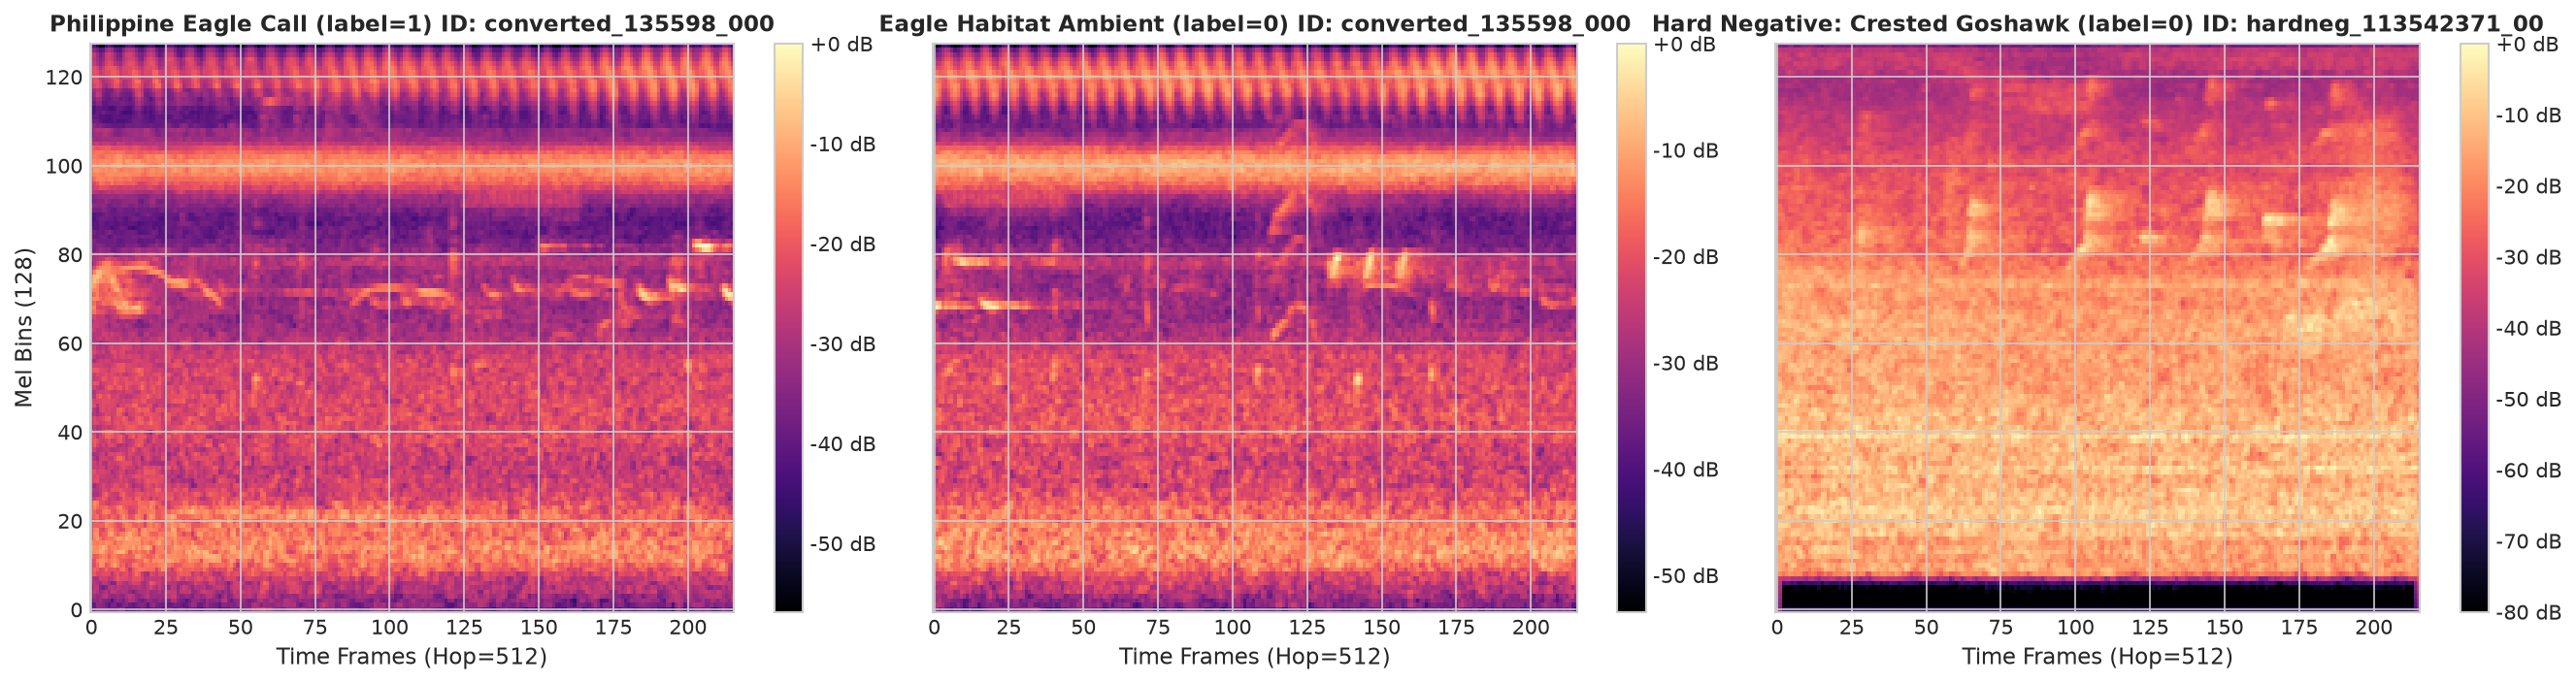

5.0s Mel Spectrogram Array Shape: (128, 216) (Expected: 128, 216)


In [7]:
# Inspect and visualize sample 5.0s Mel Spectrograms (3-Way Comparison)
sample_eagle = df_clean_5s[df_clean_5s["label"] == 1].iloc[0]
sample_bg = df_clean_5s[(df_clean_5s["label"] == 0) & (df_clean_5s["dataset_source"] == "eagle-audios")].iloc[0]

# Sample a hard negative raptor call if available, otherwise fallback
hard_neg_candidates = df_clean_5s[(df_clean_5s["label"] == 0) & (df_clean_5s["dataset_source"] == "hard-negatives")]
sample_hardneg = hard_neg_candidates.iloc[0] if len(hard_neg_candidates) > 0 else sample_bg

mel_eagle_5s = np.load(mel_5s_dir / f"{sample_eagle['slice_id']}.npy")
mel_bg_5s = np.load(mel_5s_dir / f"{sample_bg['slice_id']}.npy")
mel_hardneg_5s = np.load(mel_5s_dir / f"{sample_hardneg['slice_id']}.npy")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)

# Panel 1: Philippine Eagle Call
im0 = axes[0].imshow(mel_eagle_5s, aspect="auto", origin="lower", cmap="magma")
axes[0].set_title(f"Philippine Eagle Call (label=1) ID: {sample_eagle['slice_id'][:20]}", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Time Frames (Hop=512)")
axes[0].set_ylabel("Mel Bins (128)")
plt.colorbar(im0, ax=axes[0], format="%+2.0f dB")

# Panel 2: Eagle Territory Ambient
im1 = axes[1].imshow(mel_bg_5s, aspect="auto", origin="lower", cmap="magma")
axes[1].set_title(f"Eagle Habitat Ambient (label=0) ID: {sample_bg['slice_id'][:20]}", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Time Frames (Hop=512)")
plt.colorbar(im1, ax=axes[1], format="%+2.0f dB")

# Panel 3: Sympatric Hard Negative Raptor Call
im2 = axes[2].imshow(mel_hardneg_5s, aspect="auto", origin="lower", cmap="magma")
axes[2].set_title(f"Hard Negative: {sample_hardneg.get('species', 'Sympatric Raptor')} (label=0) ID: {sample_hardneg['slice_id'][:20]}", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Time Frames (Hop=512)")
plt.colorbar(im2, ax=axes[2], format="%+2.0f dB")

plt.tight_layout()
fig_path = SPECTROGRAMS_DIR / "5s-mel-spectrogram-sample.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved 3-way figure: {fig_path}")
plt.show()

print(f"5.0s Mel Spectrogram Array Shape: {mel_eagle_5s.shape} (Expected: 128, 216)")

### 4.3. Extract and Save 5.0-Second PCEN Mel Spectrograms

In [8]:
# Extract 5.0-second PCEN Spectrograms (with ±1 semitone pitch augmentation on eagle calls)
pcen_5s_dir = FEATURES_5S_DIR / "pcen-melSpectrogram"
batch_extract_features(
    df=df_clean_5s,
    audio_dir=AUDIO_5S_DIR,
    output_dir=pcen_5s_dir,
    feature_type="pcen",
    desc="5.0s PCEN Spectrograms",
    expected_frames=216,
    augment_minority=True
)

5.0s PCEN Spectrograms: 100%|██████████████████████████| 8828/8828 [00:00<00:00, 13750.98it/s]


[PCEN] Done. Newly extracted: 0, Skipped (cached): 11679
Saved 11679 feature metadata records to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram/features_metadata.csv
Class distribution after pitch-shift augmentation:
label
0    5977
1    5702
Name: count, dtype: int64


### 4.4. Visual Comparison: 5.0-Second PCEN Mel Spectrograms (Eagle vs. Background)

Saved 3-way figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/spectrograms/5s-pcen-spectrogram-sample.png


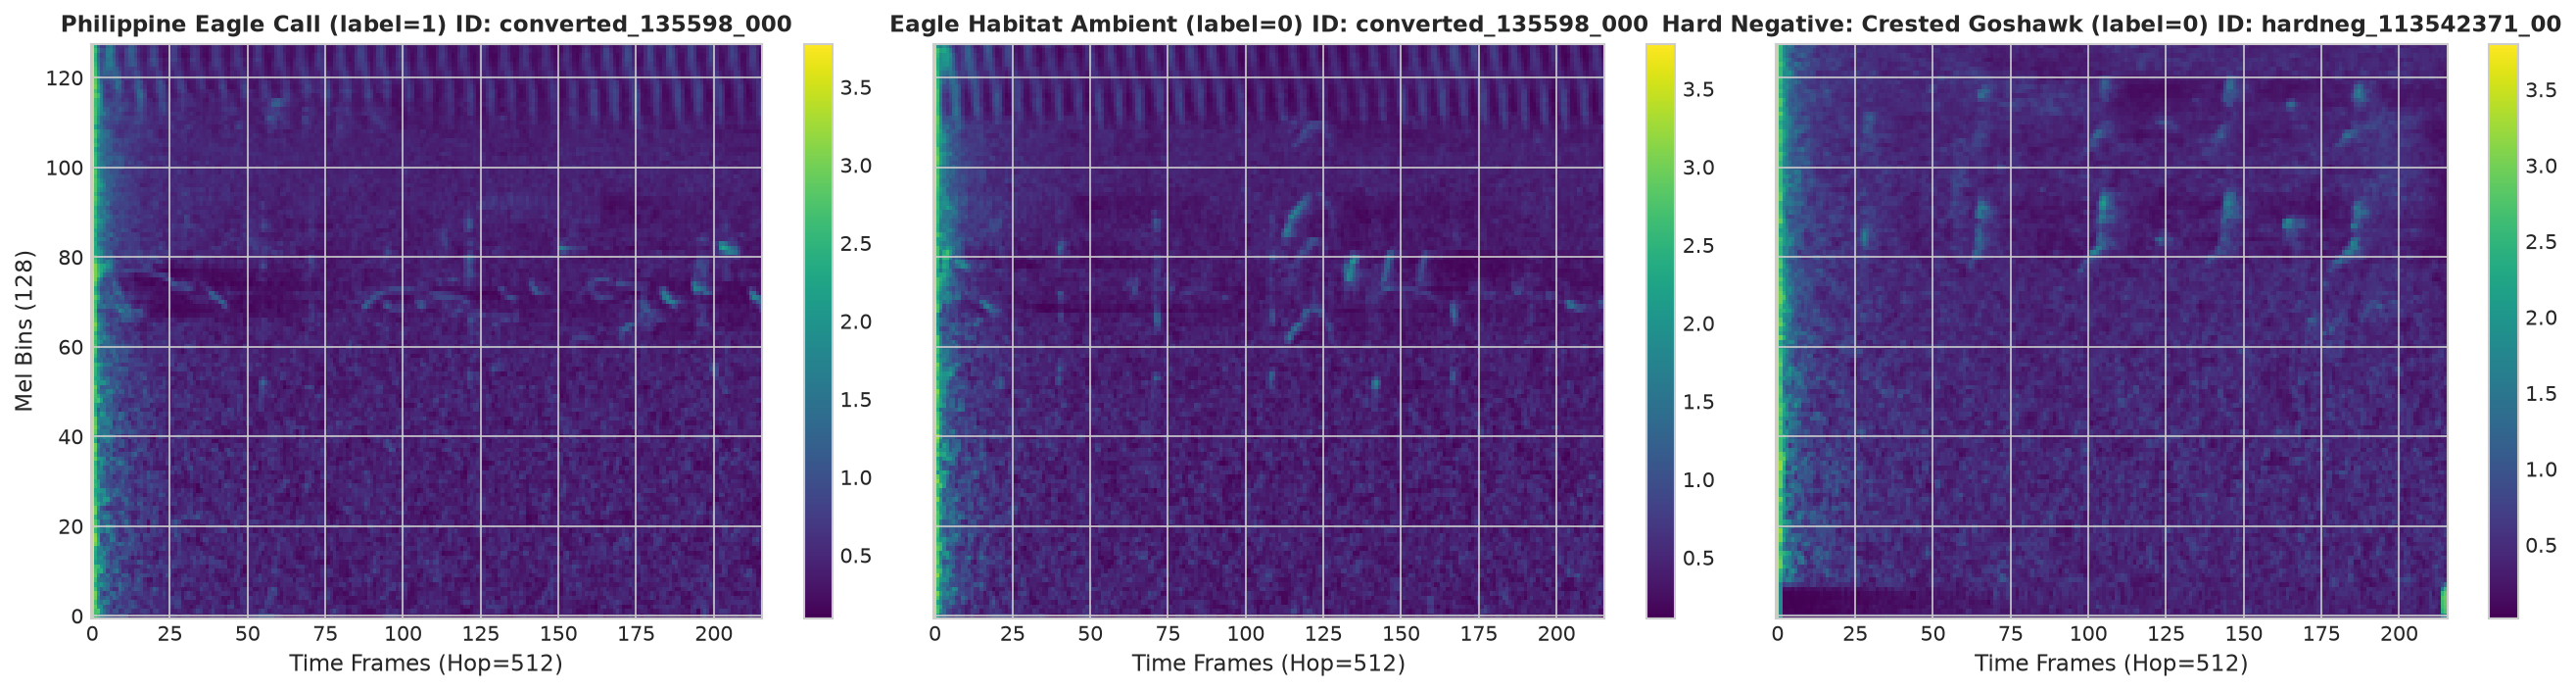

5.0s PCEN Spectrogram Array Shape: (128, 216) (Expected: 128, 216)


In [9]:
# Inspect and visualize sample 5.0s PCEN Spectrograms (3-Way Comparison)
pcen_eagle_5s = np.load(pcen_5s_dir / f"{sample_eagle['slice_id']}.npy")
pcen_bg_5s = np.load(pcen_5s_dir / f"{sample_bg['slice_id']}.npy")
pcen_hardneg_5s = np.load(pcen_5s_dir / f"{sample_hardneg['slice_id']}.npy")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)

# Panel 1: Philippine Eagle Call
im0 = axes[0].imshow(pcen_eagle_5s, aspect="auto", origin="lower", cmap="viridis")
axes[0].set_title(f"Philippine Eagle Call (label=1) ID: {sample_eagle['slice_id'][:20]}", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Time Frames (Hop=512)")
axes[0].set_ylabel("Mel Bins (128)")
plt.colorbar(im0, ax=axes[0], format="%.1f")

# Panel 2: Eagle Territory Ambient
im1 = axes[1].imshow(pcen_bg_5s, aspect="auto", origin="lower", cmap="viridis")
axes[1].set_title(f"Eagle Habitat Ambient (label=0) ID: {sample_bg['slice_id'][:20]}", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Time Frames (Hop=512)")
plt.colorbar(im1, ax=axes[1], format="%.1f")

# Panel 3: Sympatric Hard Negative Raptor Call
im2 = axes[2].imshow(pcen_hardneg_5s, aspect="auto", origin="lower", cmap="viridis")
axes[2].set_title(f"Hard Negative: {sample_hardneg.get('species', 'Sympatric Raptor')} (label=0) ID: {sample_hardneg['slice_id'][:20]}", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Time Frames (Hop=512)")
plt.colorbar(im2, ax=axes[2], format="%.1f")

plt.tight_layout()
fig_path = SPECTROGRAMS_DIR / "5s-pcen-spectrogram-sample.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved 3-way figure: {fig_path}")
plt.show()

print(f"5.0s PCEN Spectrogram Array Shape: {pcen_eagle_5s.shape} (Expected: 128, 216)")

### 4.5. Summary and Verification of 5.0-Second Feature Arrays

In [10]:
# Verification of 5.0s feature arrays on disk
mel_5s_files = list(mel_5s_dir.glob("*.npy"))
pcen_5s_files = list(pcen_5s_dir.glob("*.npy"))

print("=" * 60)
print("5.0-SECOND FEATURE EXTRACTION SUMMARY")
print("=" * 60)
print(f"Target Clean Snippets:       {len(df_clean_5s)}")
print(f"Mel Spectrogram Arrays:      {len(mel_5s_files)}")
print(f"PCEN Spectrogram Arrays:     {len(pcen_5s_files)}")
print(f"Mel Spectrogram Directory:   {mel_5s_dir}")
print(f"PCEN Spectrogram Directory:  {pcen_5s_dir}")
print("=" * 60)

5.0-SECOND FEATURE EXTRACTION SUMMARY
Target Clean Snippets:       8828
Mel Spectrogram Arrays:      11679
PCEN Spectrogram Arrays:     11679
Mel Spectrogram Directory:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/melSpectrogram
PCEN Spectrogram Directory:  /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram


### 4.6. Visualize 5.0-Second Distributions after Offline Augmentation (Class, Category, Site, and Species)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/5s-augmented-class-distribution.png


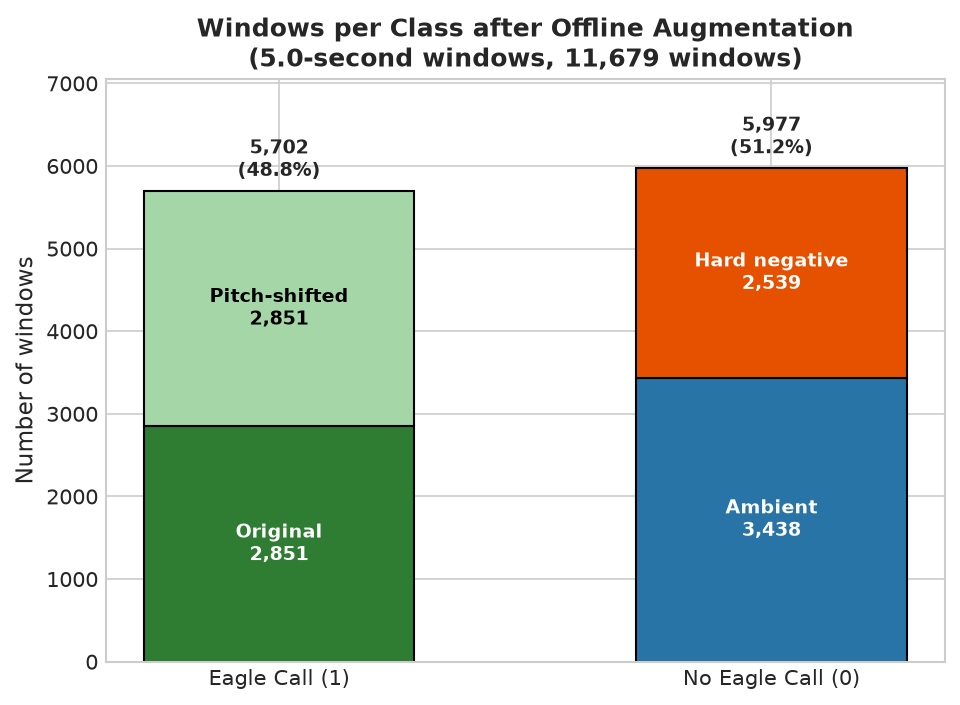

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/5s-augmented-category-distribution.png


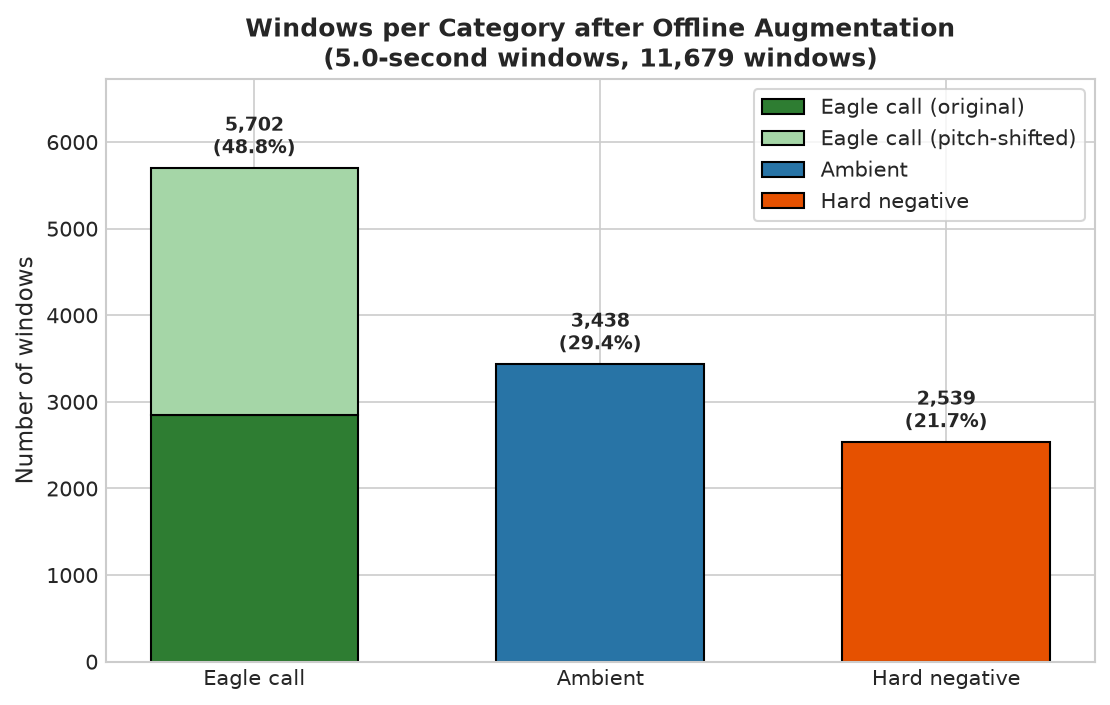

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/5s-augmented-eagle-site-distribution.png


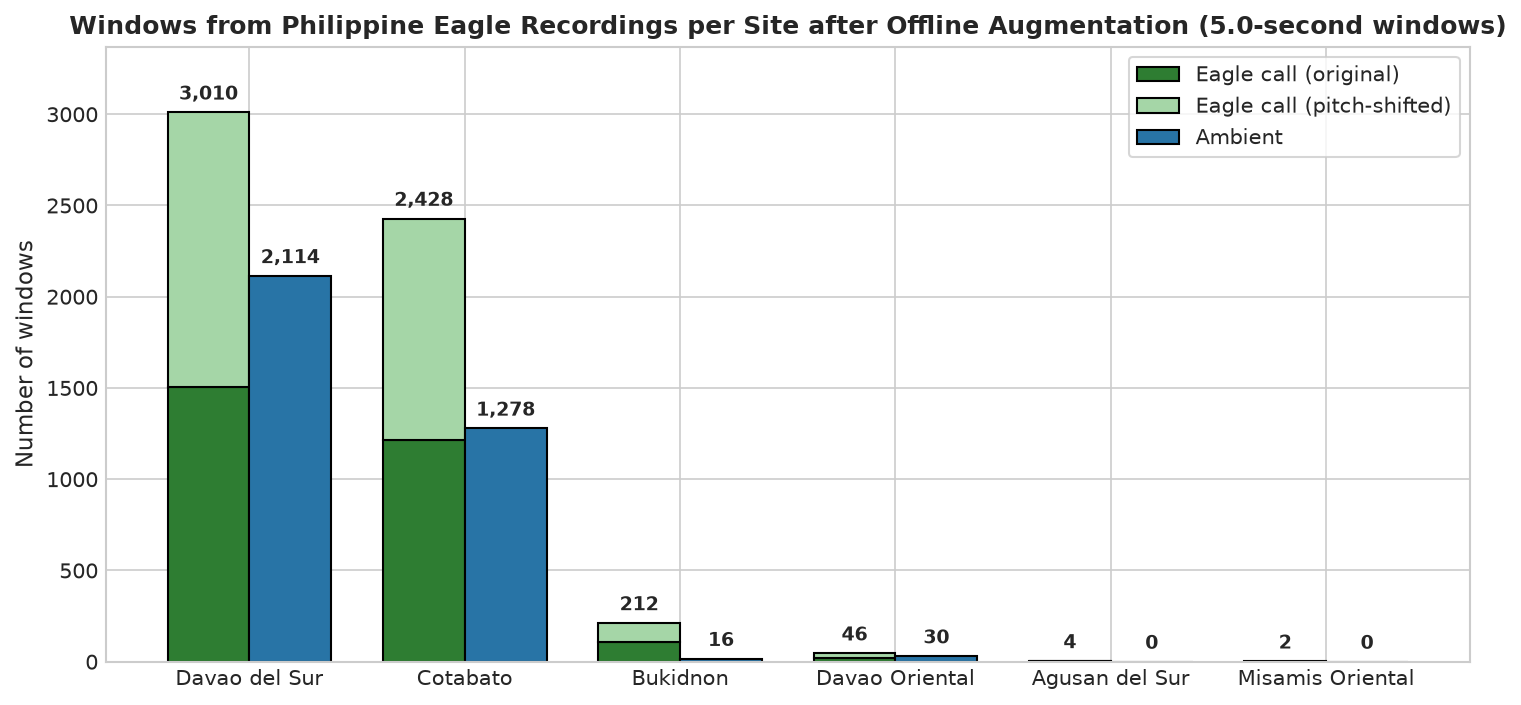

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/5s-augmented-hard-negative-species-distribution.png


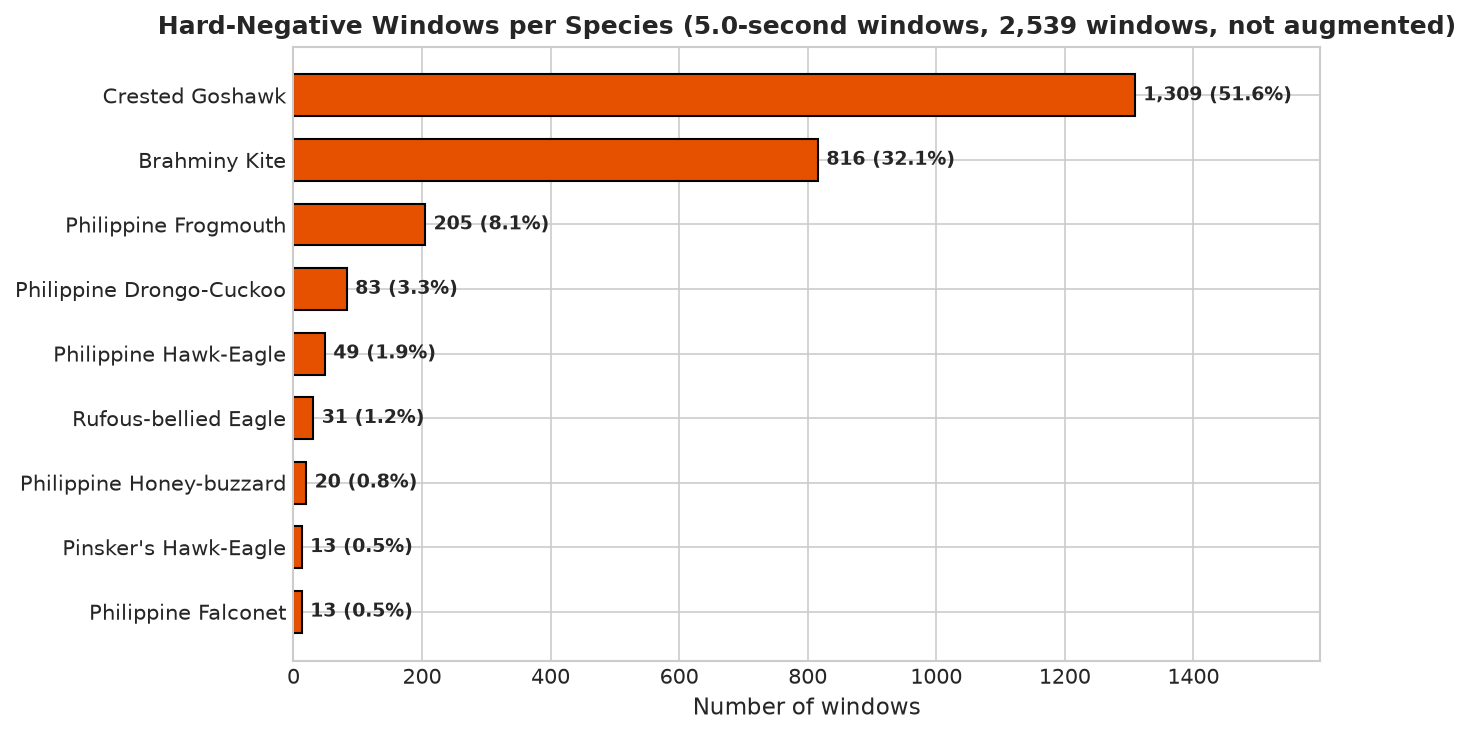

Windows after offline augmentation: 11,679 (2,851 pitch-shifted eagle copies added)


,windows
group,
Eagle call (original),2851
Eagle call (pitch-shifted),2851
Ambient,3438
Hard negative,2539


group,Eagle call (original),Eagle call (pitch-shifted),Ambient,Eagle call (total)
site,,,,
Davao del Sur,1505,1505,2114,3010
Cotabato,1214,1214,1278,2428
Bukidnon,106,106,16,212
Davao Oriental,23,23,30,46
Agusan del Sur,2,2,0,4
Misamis Oriental,1,1,0,2


In [11]:
# Distributions of the 5.0-second windows after the pitch-shifted eagle copies were added
plot_augmented_distributions(pcen_5s_dir / "features_metadata.csv", "5s", "5.0-second windows")


## 5. Feature Extraction: 3.0-Second Windows

### 5.1. Extract and Save 3.0-Second Mel Spectrograms

In [12]:
# Extract 3.0-second Log-Mel Spectrograms (with ±1 semitone pitch augmentation on eagle calls)
mel_3s_dir = FEATURES_3S_DIR / "melSpectrogram"

if not df_clean_3s.empty:
    batch_extract_features(
        df=df_clean_3s,
        audio_dir=AUDIO_3S_DIR,
        output_dir=mel_3s_dir,
        feature_type="mel",
        desc="3.0s Mel Spectrograms",
        expected_frames=130,
        augment_minority=True
    )
else:
    print("3.0s dataset not preprocessed yet. Skipping.")

3.0s Mel Spectrograms: 100%|█████████████████████████| 11084/11084 [00:00<00:00, 13181.68it/s]


[MEL] Done. Newly extracted: 0, Skipped (cached): 14421
Saved 14421 feature metadata records to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/melSpectrogram/features_metadata.csv
Class distribution after pitch-shift augmentation:
label
0    7747
1    6674
Name: count, dtype: int64


### 5.2. Visual Comparison: 3.0-Second Mel Spectrograms (Eagle vs. Background)

Saved 3-way figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/spectrograms/3s-mel-spectrogram-sample.png


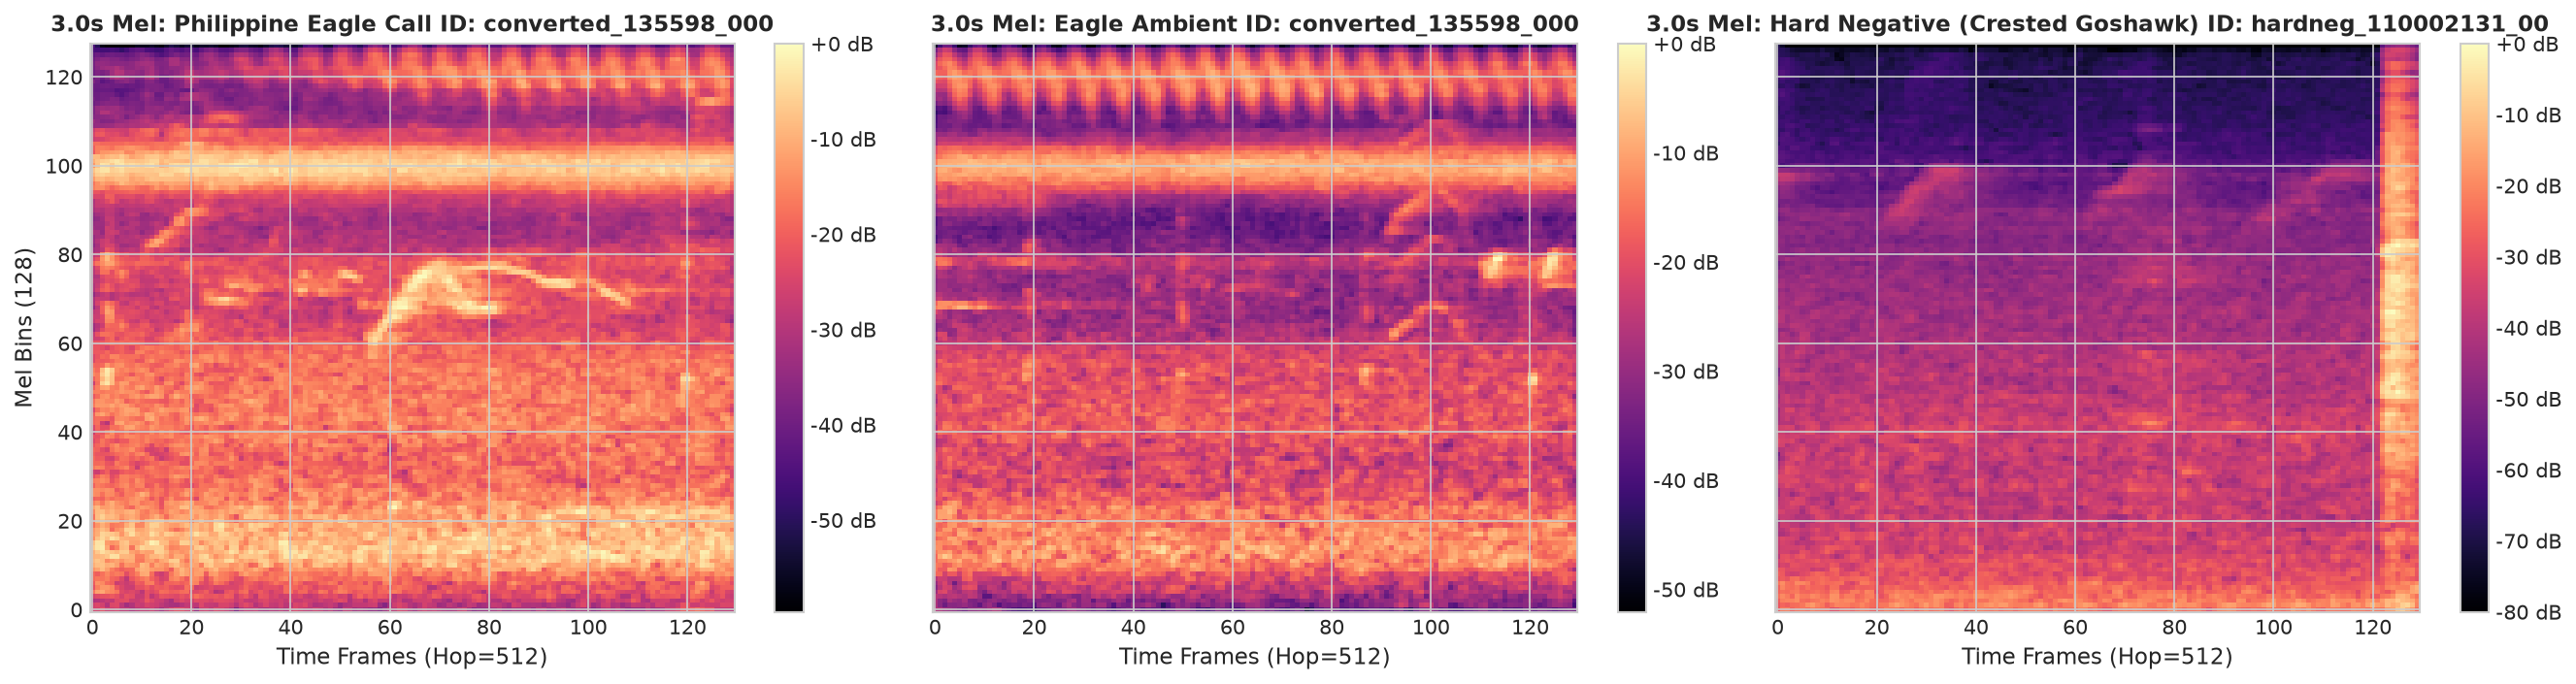

3.0s Mel Spectrogram Array Shape: (128, 130) (Expected: 128, 130)


In [13]:
# Inspect and visualize sample 3.0s Mel Spectrograms (3-Way Comparison)
if not df_clean_3s.empty and list(mel_3s_dir.glob("*.npy")):
    sample_eagle_3s = df_clean_3s[df_clean_3s["label"] == 1].iloc[0]
    sample_bg_3s = df_clean_3s[(df_clean_3s["label"] == 0) & (df_clean_3s["dataset_source"] == "eagle-audios")].iloc[0]
    hard_neg_3s = df_clean_3s[(df_clean_3s["label"] == 0) & (df_clean_3s["dataset_source"] == "hard-negatives")]
    sample_hardneg_3s = hard_neg_3s.iloc[0] if len(hard_neg_3s) > 0 else sample_bg_3s

    mel_eagle_3s = np.load(mel_3s_dir / f"{sample_eagle_3s['slice_id']}.npy")
    mel_bg_3s = np.load(mel_3s_dir / f"{sample_bg_3s['slice_id']}.npy")
    mel_hardneg_3s = np.load(mel_3s_dir / f"{sample_hardneg_3s['slice_id']}.npy")

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)

    im0 = axes[0].imshow(mel_eagle_3s, aspect="auto", origin="lower", cmap="magma")
    axes[0].set_title(f"3.0s Mel: Philippine Eagle Call ID: {sample_eagle_3s['slice_id'][:20]}", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Time Frames (Hop=512)")
    axes[0].set_ylabel("Mel Bins (128)")
    plt.colorbar(im0, ax=axes[0], format="%+2.0f dB")

    im1 = axes[1].imshow(mel_bg_3s, aspect="auto", origin="lower", cmap="magma")
    axes[1].set_title(f"3.0s Mel: Eagle Ambient ID: {sample_bg_3s['slice_id'][:20]}", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Time Frames (Hop=512)")
    plt.colorbar(im1, ax=axes[1], format="%+2.0f dB")

    im2 = axes[2].imshow(mel_hardneg_3s, aspect="auto", origin="lower", cmap="magma")
    axes[2].set_title(f"3.0s Mel: Hard Negative ({sample_hardneg_3s.get('species', 'Raptor')}) ID: {sample_hardneg_3s['slice_id'][:20]}", fontsize=11, fontweight="bold")
    axes[2].set_xlabel("Time Frames (Hop=512)")
    plt.colorbar(im2, ax=axes[2], format="%+2.0f dB")

    plt.tight_layout()
    fig_path = SPECTROGRAMS_DIR / "3s-mel-spectrogram-sample.png"
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    print(f"Saved 3-way figure: {fig_path}")
    plt.show()

    print(f"3.0s Mel Spectrogram Array Shape: {mel_eagle_3s.shape} (Expected: 128, 130)")
else:
    print("3.0s Mel feature arrays not found on disk. Run Section 5.1 first.")

### 5.3. Extract and Save 3.0-Second PCEN Mel Spectrograms

In [14]:
# Extract 3.0-second PCEN Spectrograms (with ±1 semitone pitch augmentation on eagle calls)
pcen_3s_dir = FEATURES_3S_DIR / "pcen-melSpectrogram"

if not df_clean_3s.empty:
    batch_extract_features(
        df=df_clean_3s,
        audio_dir=AUDIO_3S_DIR,
        output_dir=pcen_3s_dir,
        feature_type="pcen",
        desc="3.0s PCEN Spectrograms",
        expected_frames=130,
        augment_minority=True
    )
else:
    print("3.0s dataset not preprocessed yet. Skipping.")

3.0s PCEN Spectrograms: 100%|████████████████████████| 11084/11084 [00:00<00:00, 14137.38it/s]


[PCEN] Done. Newly extracted: 0, Skipped (cached): 14421
Saved 14421 feature metadata records to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram/features_metadata.csv
Class distribution after pitch-shift augmentation:
label
0    7747
1    6674
Name: count, dtype: int64


### 5.4. Visual Comparison: 3.0-Second PCEN Mel Spectrograms (Eagle vs. Background)

Saved 3-way figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/spectrograms/3s-pcen-spectrogram-sample.png


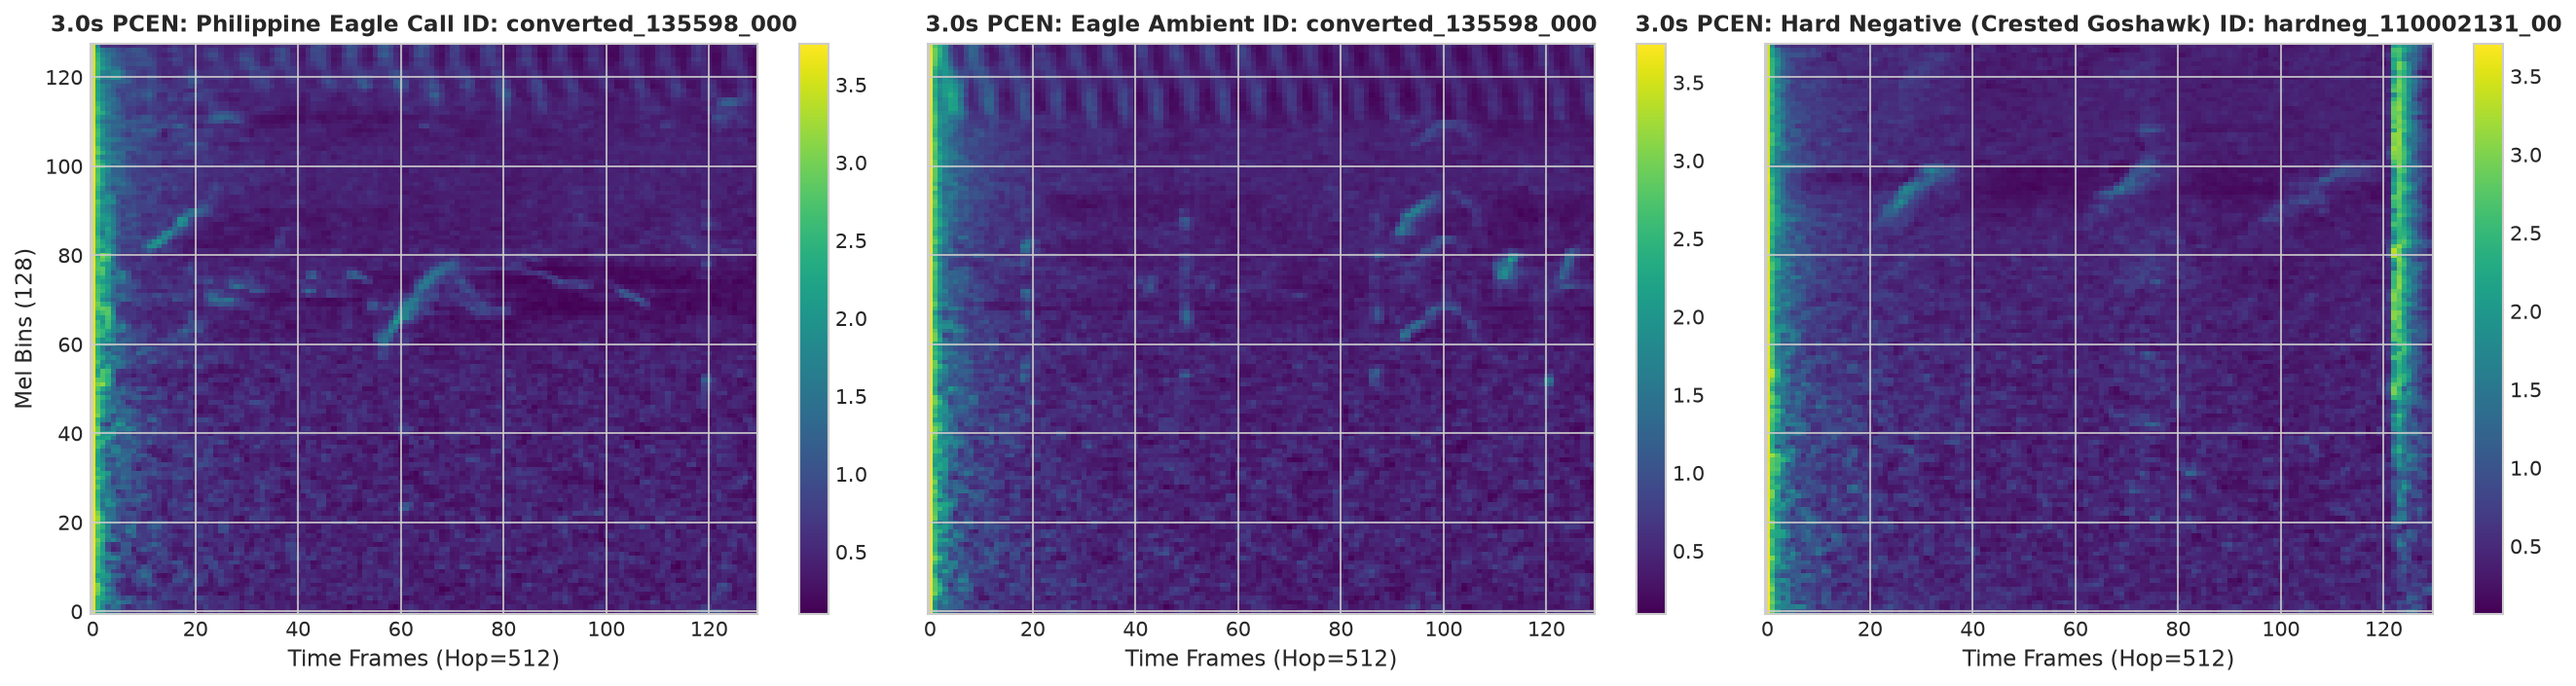

3.0s PCEN Spectrogram Array Shape: (128, 130) (Expected: 128, 130)


In [15]:
# Inspect and visualize sample 3.0s PCEN Spectrograms (3-Way Comparison)
if not df_clean_3s.empty and list(pcen_3s_dir.glob("*.npy")):
    sample_eagle_3s = df_clean_3s[df_clean_3s["label"] == 1].iloc[0]
    sample_bg_3s = df_clean_3s[(df_clean_3s["label"] == 0) & (df_clean_3s["dataset_source"] == "eagle-audios")].iloc[0]
    hard_neg_3s = df_clean_3s[(df_clean_3s["label"] == 0) & (df_clean_3s["dataset_source"] == "hard-negatives")]
    sample_hardneg_3s = hard_neg_3s.iloc[0] if len(hard_neg_3s) > 0 else sample_bg_3s

    pcen_eagle_3s = np.load(pcen_3s_dir / f"{sample_eagle_3s['slice_id']}.npy")
    pcen_bg_3s = np.load(pcen_3s_dir / f"{sample_bg_3s['slice_id']}.npy")
    pcen_hardneg_3s = np.load(pcen_3s_dir / f"{sample_hardneg_3s['slice_id']}.npy")

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)

    im0 = axes[0].imshow(pcen_eagle_3s, aspect="auto", origin="lower", cmap="viridis")
    axes[0].set_title(f"3.0s PCEN: Philippine Eagle Call ID: {sample_eagle_3s['slice_id'][:20]}", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Time Frames (Hop=512)")
    axes[0].set_ylabel("Mel Bins (128)")
    plt.colorbar(im0, ax=axes[0], format="%.1f")

    im1 = axes[1].imshow(pcen_bg_3s, aspect="auto", origin="lower", cmap="viridis")
    axes[1].set_title(f"3.0s PCEN: Eagle Ambient ID: {sample_bg_3s['slice_id'][:20]}", fontsize=11, fontweight="bold")
    axes[1].set_xlabel("Time Frames (Hop=512)")
    plt.colorbar(im1, ax=axes[1], format="%.1f")

    im2 = axes[2].imshow(pcen_hardneg_3s, aspect="auto", origin="lower", cmap="viridis")
    axes[2].set_title(f"3.0s PCEN: Hard Negative ({sample_hardneg_3s.get('species', 'Raptor')}) ID: {sample_hardneg_3s['slice_id'][:20]}", fontsize=11, fontweight="bold")
    axes[2].set_xlabel("Time Frames (Hop=512)")
    plt.colorbar(im2, ax=axes[2], format="%.1f")

    plt.tight_layout()
    fig_path = SPECTROGRAMS_DIR / "3s-pcen-spectrogram-sample.png"
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    print(f"Saved 3-way figure: {fig_path}")
    plt.show()

    print(f"3.0s PCEN Spectrogram Array Shape: {pcen_eagle_3s.shape} (Expected: 128, 130)")
else:
    print("3.0s PCEN feature arrays not found on disk. Run Section 5.3 first.")

### 5.5. Summary and Verification of 3.0-Second Feature Arrays

In [16]:
# Verification of 3.0s feature arrays on disk
mel_3s_files = list(mel_3s_dir.glob("*.npy"))
pcen_3s_files = list(pcen_3s_dir.glob("*.npy"))

print("=" * 60)
print("3.0-SECOND FEATURE EXTRACTION SUMMARY")
print("=" * 60)
print(f"Target Clean Snippets:       {len(df_clean_3s)}")
print(f"Mel Spectrogram Arrays:      {len(mel_3s_files)}")
print(f"PCEN Spectrogram Arrays:     {len(pcen_3s_files)}")
print(f"Mel Spectrogram Directory:   {mel_3s_dir}")
print(f"PCEN Spectrogram Directory:  {pcen_3s_dir}")
print("=" * 60)

3.0-SECOND FEATURE EXTRACTION SUMMARY
Target Clean Snippets:       11084
Mel Spectrogram Arrays:      14421
PCEN Spectrogram Arrays:     14421
Mel Spectrogram Directory:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/melSpectrogram
PCEN Spectrogram Directory:  /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram


### 5.6. Visualize 3.0-Second Distributions after Offline Augmentation (Class, Category, Site, and Species)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/3s-augmented-class-distribution.png


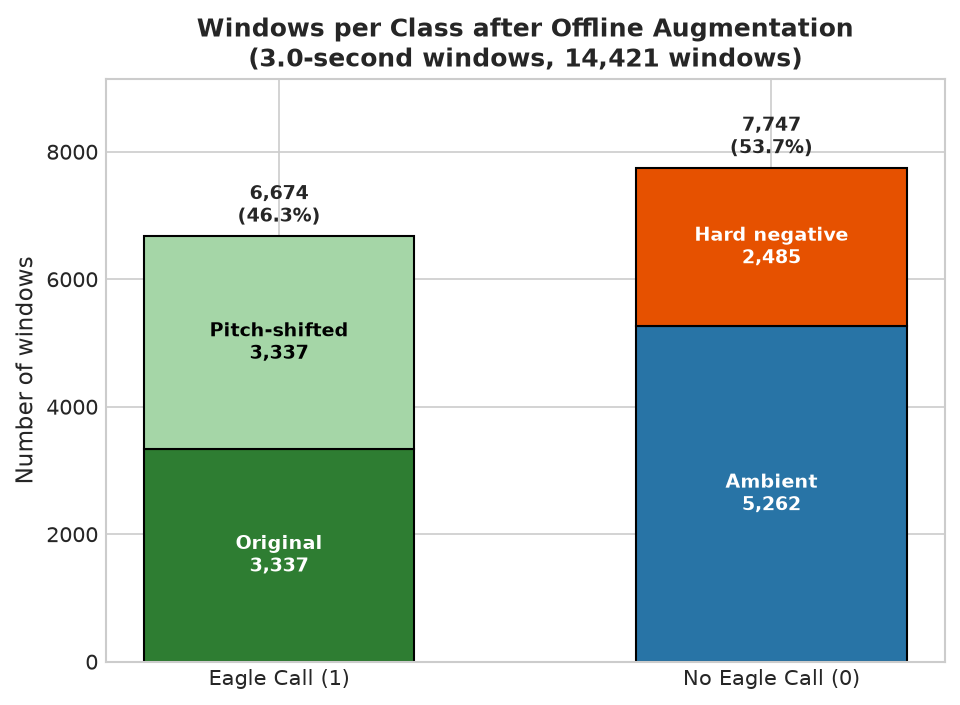

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/3s-augmented-category-distribution.png


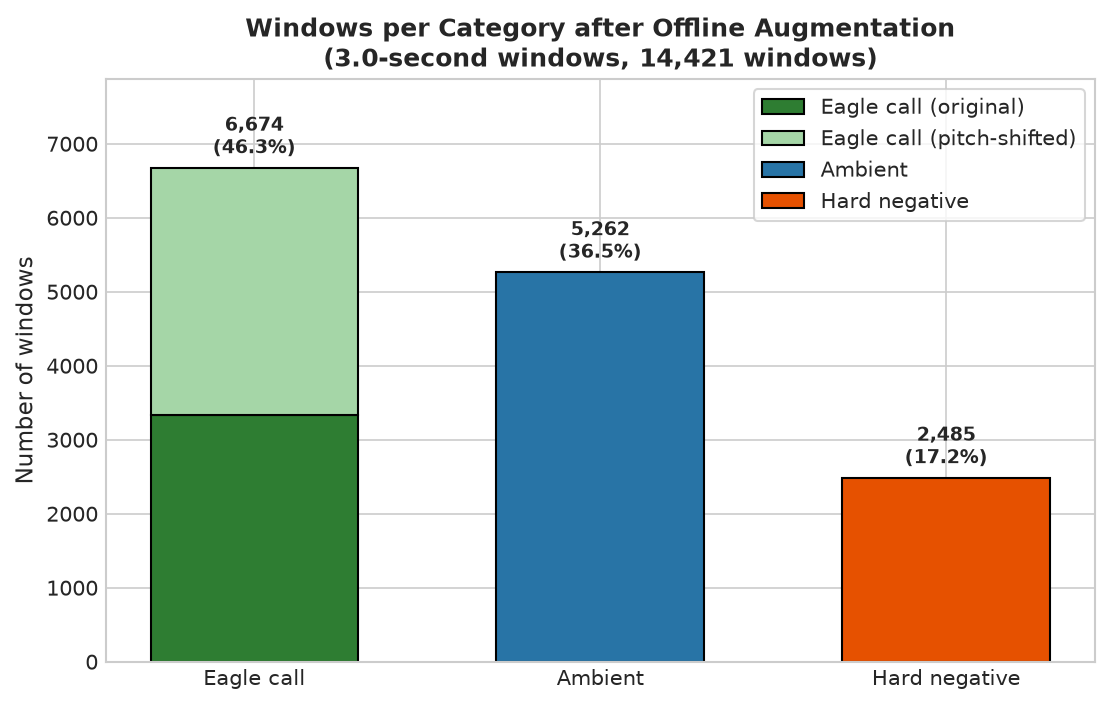

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/3s-augmented-eagle-site-distribution.png


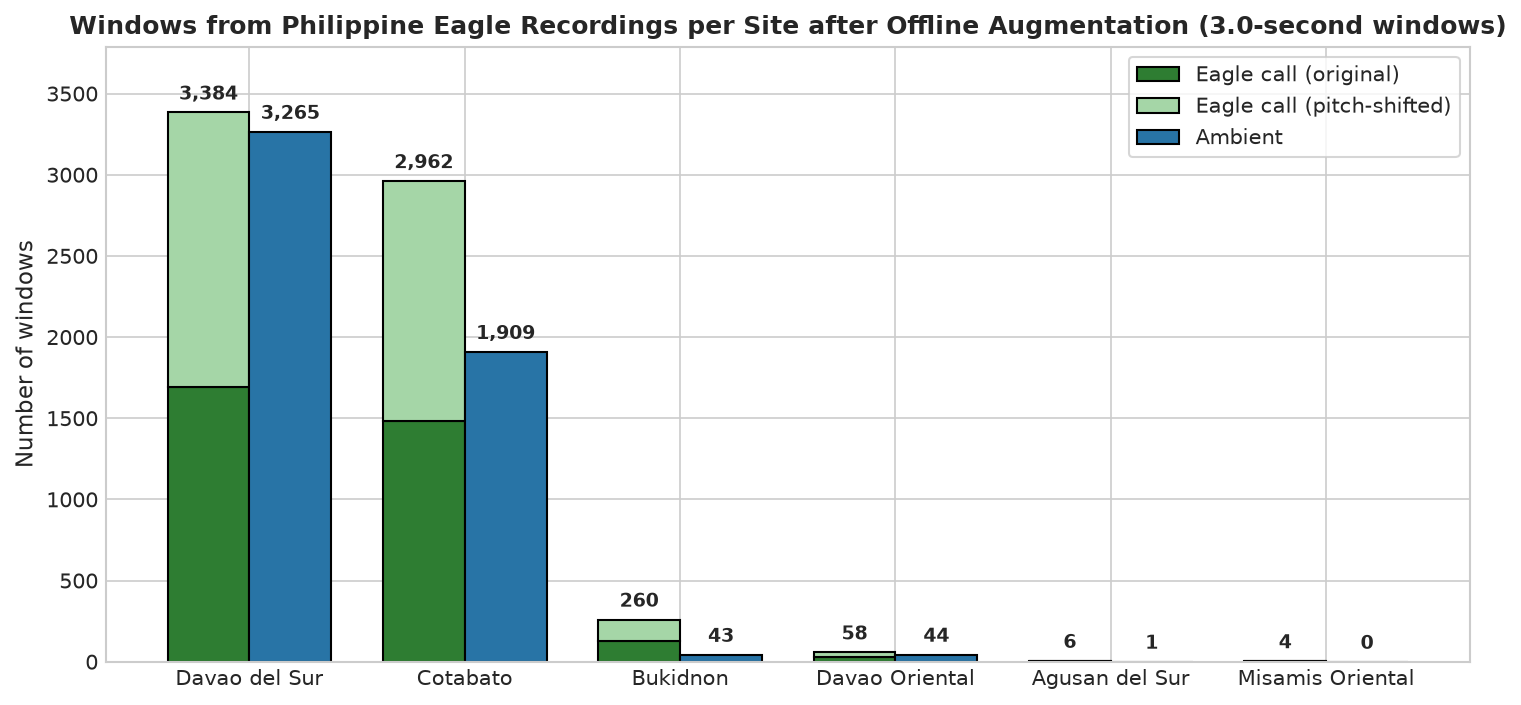

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/3s-augmented-hard-negative-species-distribution.png


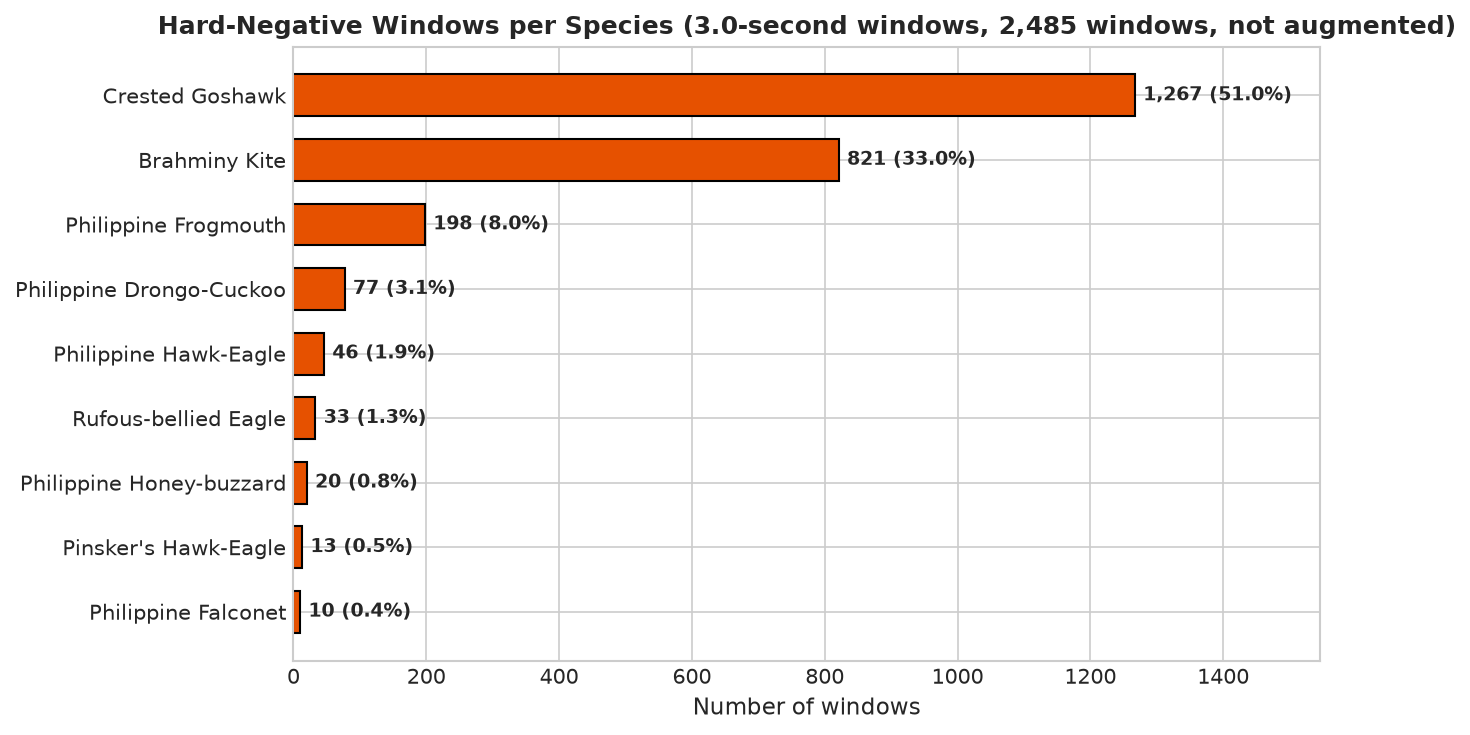

Windows after offline augmentation: 14,421 (3,337 pitch-shifted eagle copies added)


,windows
group,
Eagle call (original),3337
Eagle call (pitch-shifted),3337
Ambient,5262
Hard negative,2485


group,Eagle call (original),Eagle call (pitch-shifted),Ambient,Eagle call (total)
site,,,,
Davao del Sur,1692,1692,3265,3384
Cotabato,1481,1481,1909,2962
Bukidnon,130,130,43,260
Davao Oriental,29,29,44,58
Agusan del Sur,3,3,1,6
Misamis Oriental,2,2,0,4


In [17]:
# Distributions of the 3.0-second windows after the pitch-shifted eagle copies were added
plot_augmented_distributions(pcen_3s_dir / "features_metadata.csv", "3s", "3.0-second windows")


## 6. Multi-Scale Comparison and Visualizations

### 6.1. Side-by-Side Spectrogram Dimension & Statistics Comparison

In [18]:
# Dimension and property comparison table
comparison_data = [
    {
        "Window Scale": "5.0 Seconds",
        "Target SR (Hz)": TARGET_SR,
        "FFT / Hop Length": f"{N_FFT} / {HOP_LENGTH}",
        "Mel Bins": N_MELS,
        "Time Frames": 216,
        "Array Shape": "(128, 216)",
        "Array Size (KB)": round((128 * 216 * 4) / 1024, 2),
        "Total Snippets": len(df_clean_5s),
        "Primary Use Case": "Standard Temporal Modeling (CRNN-GRU, Conformer)"
    },
    {
        "Window Scale": "3.0 Seconds",
        "Target SR (Hz)": TARGET_SR,
        "FFT / Hop Length": f"{N_FFT} / {HOP_LENGTH}",
        "Mel Bins": N_MELS,
        "Time Frames": 130,
        "Array Shape": "(128, 130)",
        "Array Size (KB)": round((128 * 130 * 4) / 1024, 2),
        "Total Snippets": len(df_clean_3s),
        "Primary Use Case": "Low-Latency Edge Deployments & Bioacoustic Pretraining"
    }
]

df_comparison = pd.DataFrame(comparison_data)
print("MULTI-SCALE SPECTROGRAM SPECIFICATION COMPARISON:")
display(df_comparison)

MULTI-SCALE SPECTROGRAM SPECIFICATION COMPARISON:


,Window Scale,Target SR (Hz),FFT / Hop Length,Mel Bins,Time Frames,Array Shape,Array Size (KB),Total Snippets,Primary Use Case
0,5.0 Seconds,22050,2048 / 512,128,216,"(128, 216)",108.0,8828,"Standard Temporal Modeling (CRNN-GRU, Conformer)"
1,3.0 Seconds,22050,2048 / 512,128,130,"(128, 130)",65.0,11084,Low-Latency Edge Deployments & Bioacoustic Pre...


### 6.2. Comparative Multi-Panel Spectrogram Visualization (5.0s vs. 3.0s)

Saved multi-scale comparison figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/spectrograms/5s-vs-3s-spectrogram-comparison.png


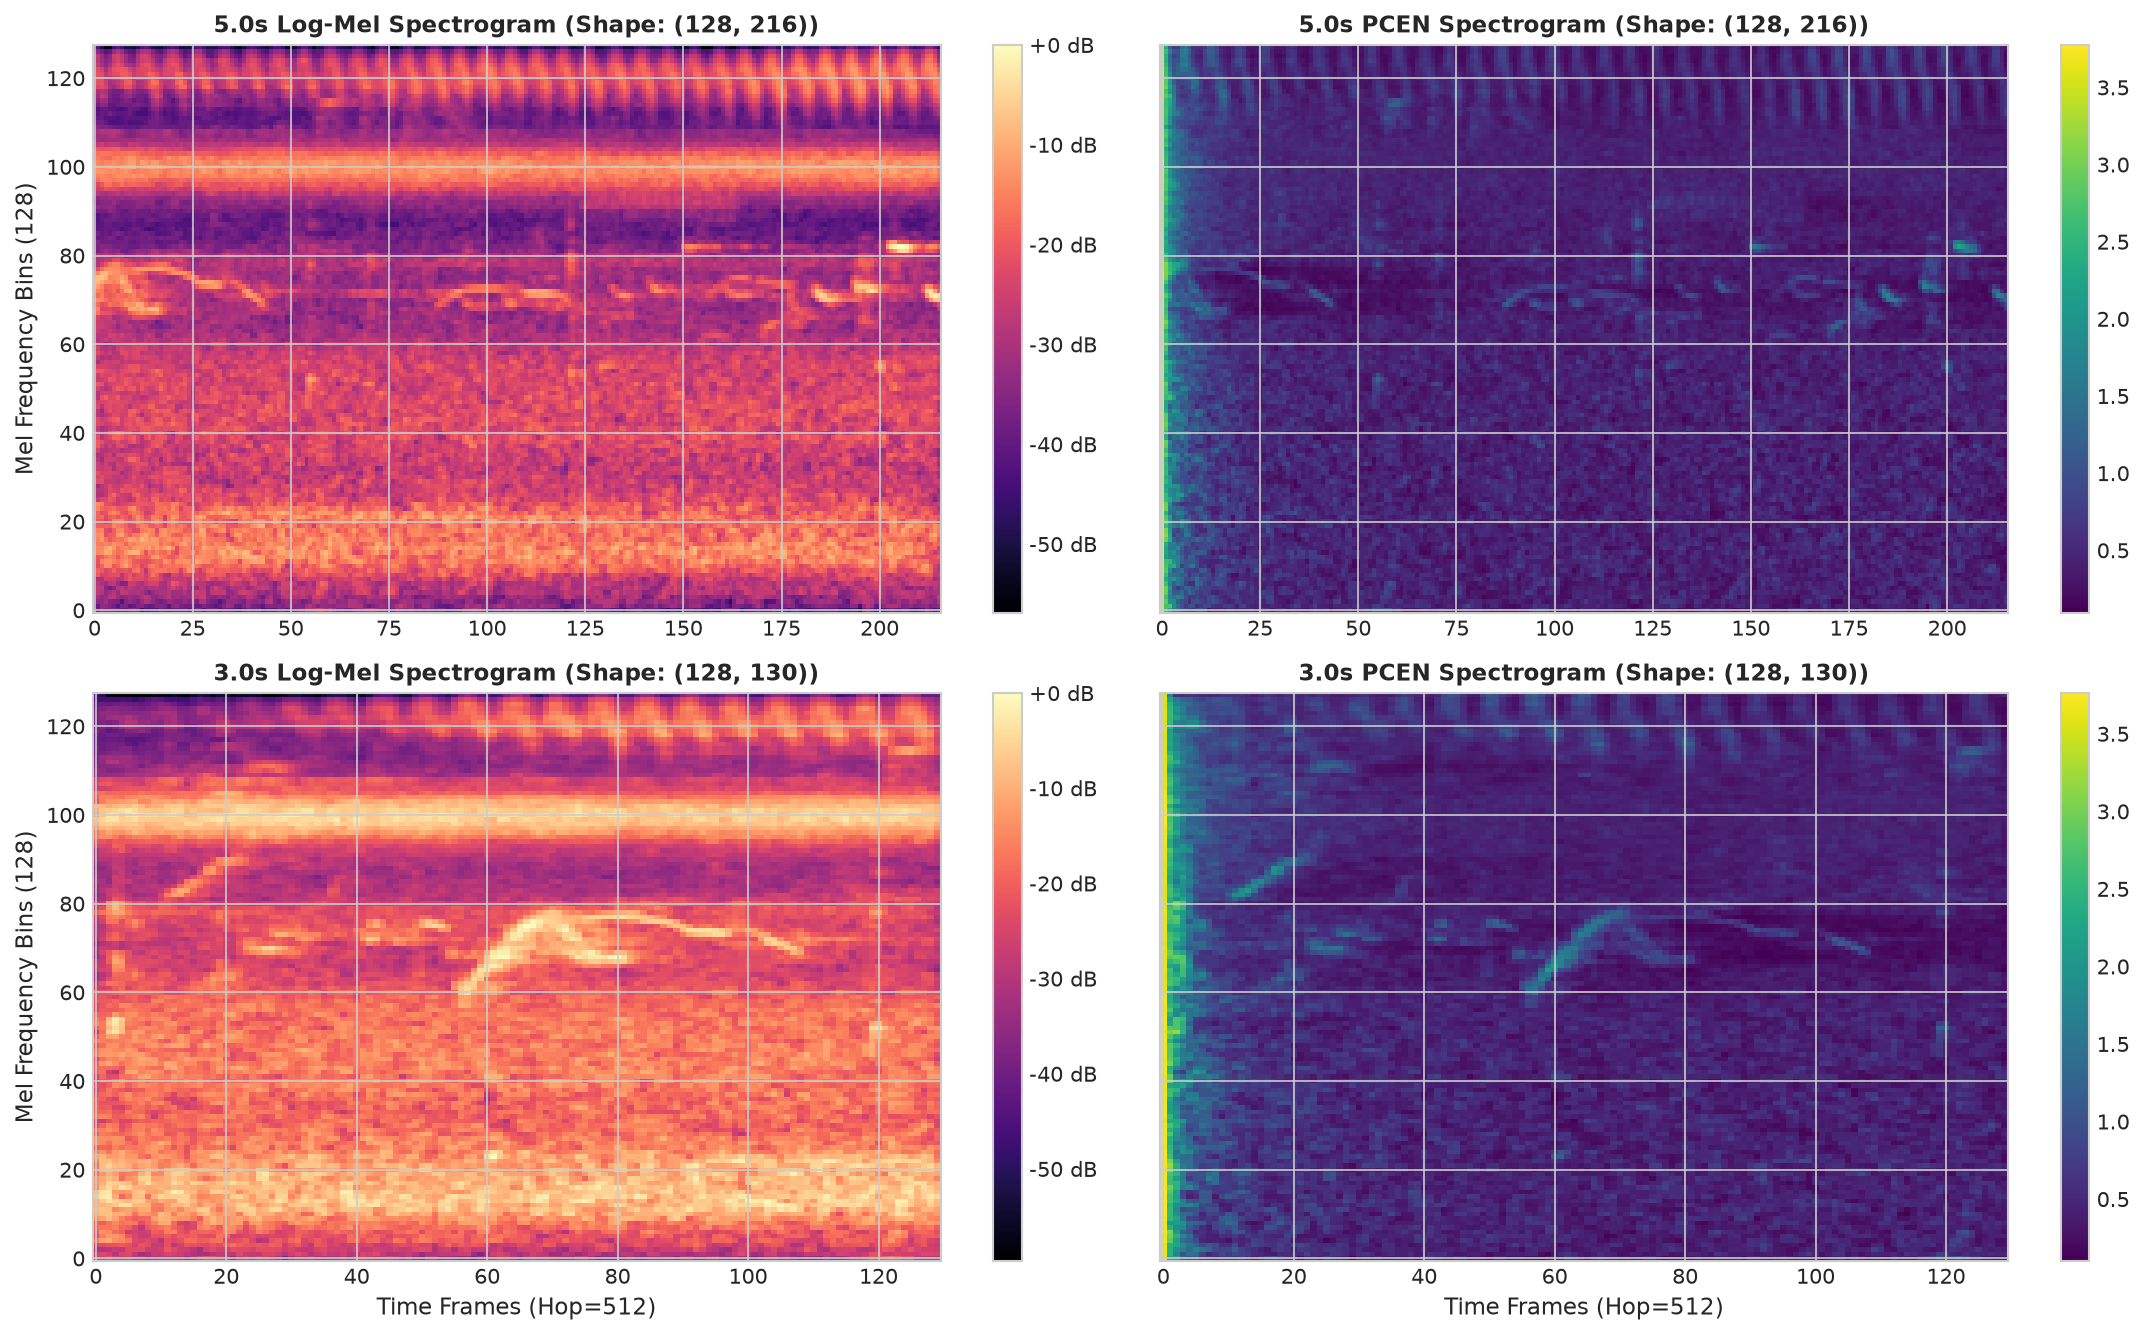

In [19]:
# 4-panel comparison: 5s vs 3s for Eagle Call
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=True)

# 5s Mel & PCEN
im00 = axes[0, 0].imshow(mel_eagle_5s, aspect="auto", origin="lower", cmap="magma")
axes[0, 0].set_title(f"5.0s Log-Mel Spectrogram (Shape: {mel_eagle_5s.shape})", fontsize=11, fontweight="bold")
axes[0, 0].set_ylabel("Mel Frequency Bins (128)")
plt.colorbar(im00, ax=axes[0, 0], format="%+2.0f dB")

im01 = axes[0, 1].imshow(pcen_eagle_5s, aspect="auto", origin="lower", cmap="viridis")
axes[0, 1].set_title(f"5.0s PCEN Spectrogram (Shape: {pcen_eagle_5s.shape})", fontsize=11, fontweight="bold")
plt.colorbar(im01, ax=axes[0, 1], format="%.1f")

# 3s Mel & PCEN (if available)
if not df_clean_3s.empty and list(mel_3s_dir.glob("*.npy")) and list(pcen_3s_dir.glob("*.npy")):
    im10 = axes[1, 0].imshow(mel_eagle_3s, aspect="auto", origin="lower", cmap="magma")
    axes[1, 0].set_title(f"3.0s Log-Mel Spectrogram (Shape: {mel_eagle_3s.shape})", fontsize=11, fontweight="bold")
    axes[1, 0].set_xlabel("Time Frames (Hop=512)")
    axes[1, 0].set_ylabel("Mel Frequency Bins (128)")
    plt.colorbar(im10, ax=axes[1, 0], format="%+2.0f dB")

    im11 = axes[1, 1].imshow(pcen_eagle_3s, aspect="auto", origin="lower", cmap="viridis")
    axes[1, 1].set_title(f"3.0s PCEN Spectrogram (Shape: {pcen_eagle_3s.shape})", fontsize=11, fontweight="bold")
    axes[1, 1].set_xlabel("Time Frames (Hop=512)")
    plt.colorbar(im11, ax=axes[1, 1], format="%.1f")
else:
    axes[1, 0].text(0.5, 0.5, "3.0s Mel Spectrogram\n(Run preprocess for 3s first)", ha="center", va="center")
    axes[1, 1].text(0.5, 0.5, "3.0s PCEN Mel Spectrogram\n(Run preprocess for 3s first)", ha="center", va="center")

plt.tight_layout()
comp_fig_path = SPECTROGRAMS_DIR / "5s-vs-3s-spectrogram-comparison.png"
fig.savefig(comp_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved multi-scale comparison figure: {comp_fig_path}")
plt.show()

### 6.3. Feature Extraction Pipeline Summary & Downstream Recommendations

In [20]:
# Summary and recommendations for model architectures
print("=" * 75)
print("FEATURE EXTRACTION PIPELINE SUMMARY & DOWNSTREAM MODEL RECOMMENDATIONS")
print("=" * 75)
print("1. 5.0-Second Representations (128, 216):")
print("   - Stored in data/features/5-seconds/pcen-melSpectrogram/")
print("   - Designed for CRNN-GRU and recurrent architectures with temporal modeling.")
print("2. 3.0-Second Representations (128, 130):")
print("   - Stored in data/features/3-seconds/pcen-melSpectrogram/")
print("   - Standard window length for bioacoustic transfer learning (e.g. BirdNET, BAD).")
print("3. PCEN vs. Log-Mel:")
print("   - PCEN dynamically suppresses steady tropical rainforest noise (rain, insect choruses).")
print("   - Retains sharp transient attack of Philippine eagle high-pitched whistles.")
print("=" * 75)

FEATURE EXTRACTION PIPELINE SUMMARY & DOWNSTREAM MODEL RECOMMENDATIONS
1. 5.0-Second Representations (128, 216):
   - Stored in data/features/5-seconds/pcen-melSpectrogram/
   - Designed for CRNN-GRU and recurrent architectures with temporal modeling.
2. 3.0-Second Representations (128, 130):
   - Stored in data/features/3-seconds/pcen-melSpectrogram/
   - Standard window length for bioacoustic transfer learning (e.g. BirdNET, BAD).
3. PCEN vs. Log-Mel:
   - PCEN dynamically suppresses steady tropical rainforest noise (rain, insect choruses).
   - Retains sharp transient attack of Philippine eagle high-pitched whistles.


## 7. BirdNET Pre-Trained Feature Embedding Extraction (3.0-Second Windows)

BirdNET takes 3.0-second audio at 48 kHz. The windows are cut from the original recordings at 48 kHz, at the same start times as the preprocessed 3.0-second clips, so BirdNET receives the full frequency range of the recordings. The PCEN Mel spectrograms in the earlier sections still use the 22,050 Hz clips.

### 7.1. Initialize BirdNET Model and Output Paths

In [21]:
import audioread
from birdnetlib.analyzer import MODEL_PATH

# BirdNET expects 48 kHz audio, so its windows are cut from the original recordings
BIRDNET_SR = 48000
BIRDNET_WINDOW_SAMPLES = int(3.0 * BIRDNET_SR)  # 144,000 samples

RAW_DIR = DATA_DIR / "raw"
RAW_AUDIO_DIRS = {
    "eagle-audios": RAW_DIR / "eagle-audios" / "audios",
    "hard-negatives": RAW_DIR / "hard-negatives" / "audios",
}

# Target directory for 3-second BirdNET embeddings
BIRDNET_3S_DIR = FEATURES_3S_DIR / "birdnet-embeddings"
BIRDNET_3S_DIR.mkdir(parents=True, exist_ok=True)

FIGURES_DIR = OUTPUTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"BirdNET model path: {MODEL_PATH}")
print(f"Model exists:       {os.path.exists(MODEL_PATH)}")
print(f"Embeddings dir:     {BIRDNET_3S_DIR}")
for source_name, source_dir in RAW_AUDIO_DIRS.items():
    print(f"Raw audio ({source_name}): {source_dir} (exists: {source_dir.exists()})")

# Initialize TFLite interpreter with intermediate tensor preservation
birdnet_interpreter = tf.lite.Interpreter(
    model_path=str(MODEL_PATH),
    experimental_preserve_all_tensors=True
)
birdnet_interpreter.allocate_tensors()

# Dynamically locate input, output, and 1,024-D embedding layer tensors
input_details = birdnet_interpreter.get_input_details()
output_details = birdnet_interpreter.get_output_details()
bn_in_idx = input_details[0]["index"]
bn_out_idx = output_details[0]["index"]

all_tensors = birdnet_interpreter.get_tensor_details()
embed_candidates = [
    t for t in all_tensors
    if len(t["shape"]) == 2 and t["shape"][1] == 1024 and "Mean" in t["name"]
]
if not embed_candidates:
    embed_candidates = [t for t in all_tensors if len(t["shape"]) == 2 and t["shape"][1] == 1024]

bn_embed_idx = embed_candidates[0]["index"]

print(f"Input tensor index:     {bn_in_idx} (shape: {input_details[0]['shape']})")
print(f"Output tensor index:    {bn_out_idx} (shape: {output_details[0]['shape']})")
print(f"Embedding tensor index: {bn_embed_idx} (name: {embed_candidates[0]['name']}, shape: {embed_candidates[0]['shape']})")

BirdNET model path: /home/fumei/Documents/MachineLearning/EagleSoundClassification/.venv/lib/python3.13/site-packages/birdnetlib/models/analyzer/BirdNET_GLOBAL_6K_V2.4_Model_FP32.tflite
Model exists:       True
Embeddings dir:     /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/birdnet-embeddings
Raw audio (eagle-audios): /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/eagle-audios/audios (exists: True)
Raw audio (hard-negatives): /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/hard-negatives/audios (exists: True)
Input tensor index:     0 (shape: [     1 144000])
Output tensor index:    546 (shape: [   1 6522])
Embedding tensor index: 545 (name: model/GLOBAL_AVG_POOL/Mean, shape: [   1 1024])


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


### 7.2. Define BirdNET Feature Extraction Function

In [22]:
def extract_birdnet_from_signal(sig, interpreter, in_idx, embed_idx, out_idx):
    """
    Extract 1,024-D feature embedding and bird confidence from a 48 kHz float32 signal (144,000 samples).
    """
    target_len = BIRDNET_WINDOW_SAMPLES
    if len(sig) < target_len:
        sig = np.pad(sig, (0, target_len - len(sig)))
    else:
        sig = sig[:target_len]
    
    sig = sig.astype(np.float32)
    
    interpreter.set_tensor(in_idx, np.expand_dims(sig, axis=0))
    interpreter.invoke()
    
    embedding = interpreter.get_tensor(embed_idx)[0].copy().astype(np.float32)
    logits = interpreter.get_tensor(out_idx)[0].astype(np.float32)
    probs = 1.0 / (1.0 + np.exp(-logits))
    max_bird_prob = float(np.max(probs))
    
    return embedding, max_bird_prob


def load_raw_audio_for_birdnet(file_path, target_sr=BIRDNET_SR):
    """
    Load an original recording (.wav, .mp3, or .m4a) as mono float32 at 48 kHz.
    """
    try:
        y, _ = librosa.load(file_path, sr=target_sr, mono=True)
        return y.astype(np.float32)
    except Exception:
        # Fallback for .m4a / AAC containers using audioread
        with audioread.audio_open(str(file_path)) as a:
            raw_bytes = b"".join([buf for buf in a])
            audio = np.frombuffer(raw_bytes, dtype=np.int16).astype(np.float32) / 32768.0
            if a.channels > 1:
                audio = audio.reshape(-1, a.channels).mean(axis=1)
            if a.samplerate != target_sr:
                audio = librosa.resample(audio, orig_sr=a.samplerate, target_sr=target_sr)
            return audio.astype(np.float32)


def cut_birdnet_window(recording, start_time, target_sr=BIRDNET_SR, window_samples=BIRDNET_WINDOW_SAMPLES):
    """
    Cut one 3.0-second window from a 48 kHz recording, starting at start_time (seconds).
    A window that runs past the end of the recording is zero-padded.
    """
    start_idx = int(round(start_time * target_sr))
    window = recording[start_idx:start_idx + window_samples]
    if len(window) < window_samples:
        window = np.pad(window, (0, window_samples - len(window)))
    return window.astype(np.float32)


### 7.3. Extract and Save 3.0-Second BirdNET Embeddings (with Caching Guard)

In [23]:
# Batch extraction with caching guards and pitch-shift augmentation across clean 3s slices.
# Every window is cut from its original recording at 48 kHz, using the start time in the metadata.
meta_birdnet_path = FEATURES_3S_DIR / "birdnet_metadata.csv"
birdnet_records = []
loaded_source = None
loaded_recording = None
missing_recordings = set()

if not df_clean_3s.empty:
    print(f"Extracting BirdNET embeddings for {len(df_clean_3s)} clean 3.0-second snippets...")

    for idx, (_, row) in enumerate(tqdm(df_clean_3s.iterrows(), total=len(df_clean_3s), desc="Extracting BirdNET Embeddings (3.0s)")):
        slice_id = row.get("slice_id") if ("slice_id" in row and pd.notna(row["slice_id"])) else Path(row["file_name"]).stem
        out_file = BIRDNET_3S_DIR / f"{slice_id}.npy"
        raw_audio_file = RAW_AUDIO_DIRS[row["dataset_source"]] / row["source_audio"]

        if not raw_audio_file.exists():
            missing_recordings.add(row["source_audio"])
            continue

        n_steps = 1.0 if (idx % 2 == 0) else -1.0
        step_tag = "p1" if n_steps > 0 else "m1"
        aug_slice_id = f"{slice_id}_ps_{step_tag}"
        aug_out_file = BIRDNET_3S_DIR / f"{aug_slice_id}.npy"
        
        # Load the original recording at 48 kHz (once per recording) if base or aug needs extraction
        need_base = not out_file.exists()
        need_aug = (row["label"] == 1) and (not aug_out_file.exists())
        
        sig = None
        if need_base or need_aug:
            if loaded_source != row["source_audio"]:
                loaded_recording = load_raw_audio_for_birdnet(raw_audio_file)
                loaded_source = row["source_audio"]
            sig = cut_birdnet_window(loaded_recording, row["start_time"])

        # 1. Base BirdNET embedding
        if out_file.exists():
            birdnet_records.append({
                "slice_id": slice_id,
                "feature_file": f"{slice_id}.npy",
                "embedding_path": str(out_file),
                "is_eagle": row["is_eagle"],
                "label": row["label"],
                "site": row.get("site", "Unknown"),
                "source_audio": row.get("source_audio", ""),
                "species": row.get("species", ""),
                "dataset_source": row.get("dataset_source", "eagle-audios"),
                "is_augmented": False,
                "augmentation_type": "none",
                "cached": True
            })
        else:
            embedding, max_bird_score = extract_birdnet_from_signal(sig, birdnet_interpreter, bn_in_idx, bn_embed_idx, bn_out_idx)
            np.save(out_file, embedding)
            birdnet_records.append({
                "slice_id": slice_id,
                "feature_file": f"{slice_id}.npy",
                "embedding_path": str(out_file),
                "max_bird_score": max_bird_score,
                "is_eagle": row["is_eagle"],
                "label": row["label"],
                "site": row.get("site", "Unknown"),
                "source_audio": row.get("source_audio", ""),
                "species": row.get("species", ""),
                "dataset_source": row.get("dataset_source", "eagle-audios"),
                "is_augmented": False,
                "augmentation_type": "none",
                "cached": False
            })

        # 2. Targeted Pitch-Shift Augmentation for Eagle Calls (label == 1)
        if row["label"] == 1:
            if aug_out_file.exists():
                birdnet_records.append({
                    "slice_id": aug_slice_id,
                    "feature_file": f"{aug_slice_id}.npy",
                    "embedding_path": str(aug_out_file),
                    "is_eagle": row["is_eagle"],
                    "label": row["label"],
                    "site": row.get("site", "Unknown"),
                    "source_audio": row.get("source_audio", ""),
                    "species": row.get("species", ""),
                    "dataset_source": row.get("dataset_source", "eagle-audios"),
                    "is_augmented": True,
                    "augmentation_type": f"pitch_shift_{step_tag}",
                    "cached": True
                })
            else:
                sig_aug = librosa.effects.pitch_shift(y=sig, sr=BIRDNET_SR, n_steps=n_steps)
                embedding_aug, max_bird_score_aug = extract_birdnet_from_signal(sig_aug, birdnet_interpreter, bn_in_idx, bn_embed_idx, bn_out_idx)
                np.save(aug_out_file, embedding_aug)
                birdnet_records.append({
                    "slice_id": aug_slice_id,
                    "feature_file": f"{aug_slice_id}.npy",
                    "embedding_path": str(aug_out_file),
                    "max_bird_score": max_bird_score_aug,
                    "is_eagle": row["is_eagle"],
                    "label": row["label"],
                    "site": row.get("site", "Unknown"),
                    "source_audio": row.get("source_audio", ""),
                    "species": row.get("species", ""),
                    "dataset_source": row.get("dataset_source", "eagle-audios"),
                    "is_augmented": True,
                    "augmentation_type": f"pitch_shift_{step_tag}",
                    "cached": False
                })

    df_birdnet_meta = pd.DataFrame(birdnet_records)
    df_birdnet_meta.to_csv(meta_birdnet_path, index=False)
    print(f"Saved {len(df_birdnet_meta)} BirdNET metadata records to: {meta_birdnet_path}")
    print(f"Newly extracted: {int((~df_birdnet_meta['cached']).sum())} | reused from disk: {int(df_birdnet_meta['cached'].sum())}")
    if missing_recordings:
        print(f"WARNING: {len(missing_recordings)} original recordings were not found; their windows were skipped.")
    print(f"Class balance after BirdNET augmentation:")
    print(df_birdnet_meta["label"].value_counts())
else:
    print("3.0s clean dataset not available. Run Section 2.2 first.")

Extracting BirdNET embeddings for 11084 clean 3.0-second snippets...


Extracting BirdNET Embeddings (3.0s):  81%|███████████▎  | 8983/11084 [07:20<01:18, 26.91it/s][src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
[src/libmpg123/id3.c:process_extra():684] error: No extra frame text / valid description?
Extracting BirdNET Embeddings (3.0s): 100%|█████████████| 11084/11084 [08:37<00:00, 21.42it/s]


Saved 14421 BirdNET metadata records to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/birdnet_metadata.csv
Newly extracted: 14421 | reused from disk: 0
Class balance after BirdNET augmentation:
label
0    7747
1    6674
Name: count, dtype: int64


### 7.4. Visual Inspection of BirdNET Embeddings (Eagle vs. Background)

Saved BirdNET embedding profile figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/feature-extraction/outputs/figures/birdnet-embedding-profile.png


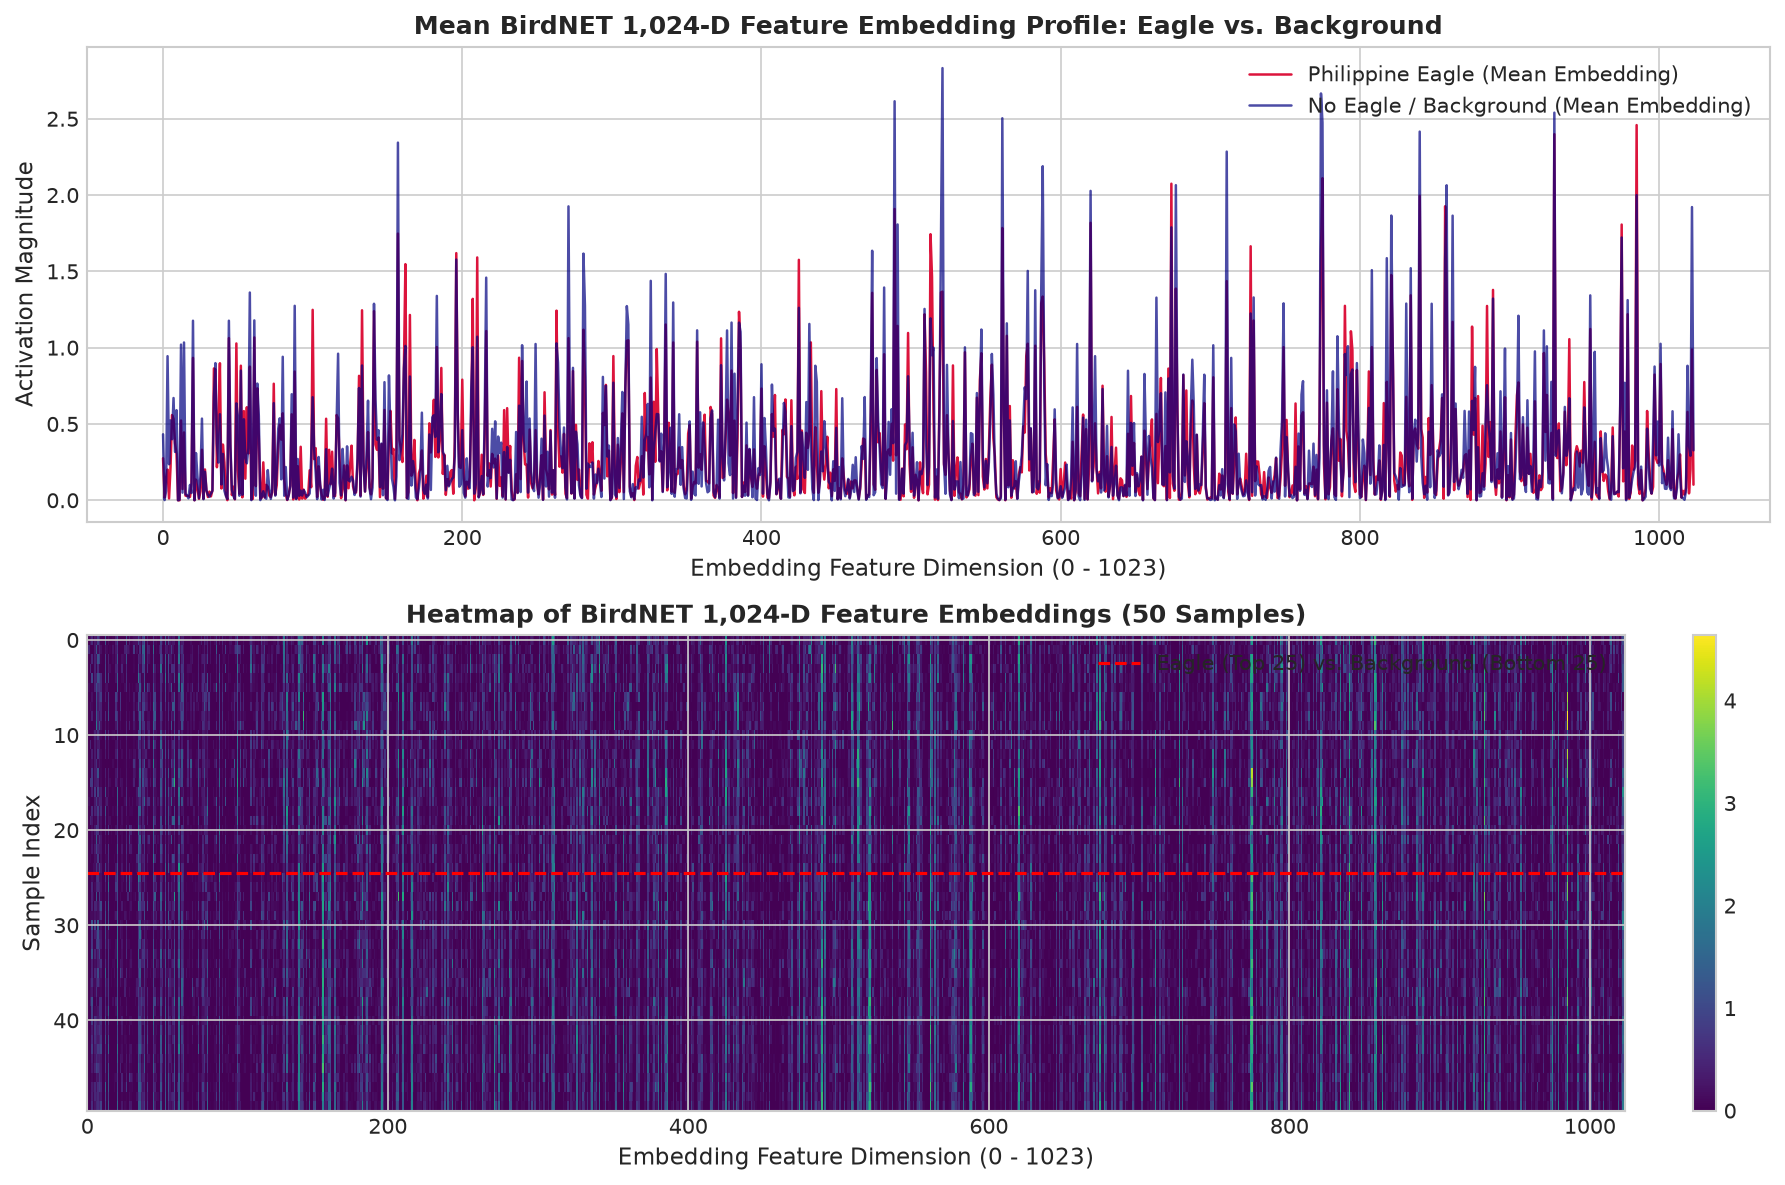

In [24]:
# Load sample embeddings to visualize class separation
if Path(meta_birdnet_path).exists() and len(list(BIRDNET_3S_DIR.glob("*.npy"))) > 0:
    df_bn_meta = pd.read_csv(meta_birdnet_path)
    sample_eagle = df_bn_meta[df_bn_meta["label"] == 1].head(100)
    sample_bg = df_bn_meta[df_bn_meta["label"] == 0].head(100)

    if len(sample_eagle) > 0 and len(sample_bg) > 0:
        eagle_embeds = np.array([np.load(p) for p in sample_eagle["embedding_path"]])
        bg_embeds = np.array([np.load(p) for p in sample_bg["embedding_path"]])

        fig, axes = plt.subplots(2, 1, figsize=(12, 8))

        # 1. Mean embedding profile
        axes[0].plot(eagle_embeds.mean(axis=0), color="crimson", lw=1.2, label="Philippine Eagle (Mean Embedding)")
        axes[0].plot(bg_embeds.mean(axis=0), color="navy", lw=1.2, alpha=0.7, label="No Eagle / Background (Mean Embedding)")
        axes[0].set_title("Mean BirdNET 1,024-D Feature Embedding Profile: Eagle vs. Background", fontsize=12, fontweight="bold")
        axes[0].set_xlabel("Embedding Feature Dimension (0 - 1023)")
        axes[0].set_ylabel("Activation Magnitude")
        axes[0].legend(loc="upper right")

        # 2. Embedding Heatmap comparison
        combined_samples = np.vstack([eagle_embeds[:25], bg_embeds[:25]])
        im = axes[1].imshow(combined_samples, aspect="auto", cmap="viridis", interpolation="nearest")
        axes[1].axhline(24.5, color="red", linestyle="--", linewidth=1.5, label="Eagle (Top 25) vs. Background (Bottom 25)")
        axes[1].set_title("Heatmap of BirdNET 1,024-D Feature Embeddings (50 Samples)", fontsize=12, fontweight="bold")
        axes[1].set_xlabel("Embedding Feature Dimension (0 - 1023)")
        axes[1].set_ylabel("Sample Index")
        axes[1].legend(loc="upper right")
        plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

        plt.tight_layout()
        fig_path = FIGURES_DIR / "birdnet-embedding-profile.png"
        fig.savefig(fig_path, dpi=300, bbox_inches="tight")
        print(f"Saved BirdNET embedding profile figure to: {fig_path}")
        plt.show()
    else:
        print("Insufficient samples for visualization.")
else:
    print("BirdNET embeddings not extracted yet. Run Section 7.3 first.")

### 7.5. Summary and Verification of BirdNET Feature Arrays

In [25]:
# Verify BirdNET feature arrays and print summary
npy_files = list(BIRDNET_3S_DIR.glob("*.npy"))
total_embeddings = len(npy_files)

if total_embeddings > 0:
    total_size_mb = sum(f.stat().st_size for f in npy_files) / (1024 * 1024)
    sample_file = npy_files[0]
    sample_arr = np.load(sample_file)

    print("=" * 75)
    print("BIRDNET EMBEDDING EXTRACTION SUMMARY & VERIFICATION")
    print("=" * 75)
    print(f"Target Directory:      {BIRDNET_3S_DIR}")
    print(f"Total .npy Files:      {total_embeddings}")
    print(f"Total Storage Size:    {total_size_mb:.2f} MB")
    print(f"Sample File:           {sample_file.name}")
    print(f"Feature Array Shape:   {sample_arr.shape}")
    print(f"Data Type:             {sample_arr.dtype}")
    print(f"Values Range:          [{sample_arr.min():.4f}, {sample_arr.max():.4f}]")
    print("Downstream Status:     READY for Transfer Learning & Cascade Training in Notebook 05!")
    print("=" * 75)
else:
    print(f"No .npy files found in {BIRDNET_3S_DIR}. Run Section 7.3 first.")

BIRDNET EMBEDDING EXTRACTION SUMMARY & VERIFICATION
Target Directory:      /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/birdnet-embeddings
Total .npy Files:      14421
Total Storage Size:    58.09 MB
Sample File:           hardneg_217253_00013.5_00016.5.npy
Feature Array Shape:   (1024,)
Data Type:             float32
Values Range:          [0.0000, 2.6839]
Downstream Status:     READY for Transfer Learning & Cascade Training in Notebook 05!
